<style>
.jp-RenderedHTMLCommon h1,.jp-RenderedHTMLCommon h2,.text_cell_render h1,.text_cell_render h2 {
font-family: "Times New Roman", "Liberation Serif", "Nimbus Roman", Georgia, serif;
font-weight: bold; color: black; padding-bottom: .24em; border-bottom: 0;
}
.jp-RenderedHTMLCommon hr,.text_cell_render hr {border: 0; border-top: 1px solid black;}
.jp-RenderedHTMLCommon,.text_cell_render {color: black;}
.jp-RenderedHTMLCommon nav,.text_cell_render nav {margin: 1em 0;}
.jp-RenderedHTMLCommon a,.text_cell_render a {color: inherit; text-decoration: underline;}
</style>

<a id="carnet"></a>

# Parallel edit distance from a single pair to genome collections

<hr>

La distance d’édition globale est le nombre minimal d’insertions, de suppressions et de substitutions qui transforme une chaîne en une autre. La programmation dynamique classique calcule jusqu’à un billion de cases pour deux séquences d’un million de bases. NvPD s’appuie sur la dernière occurrence d’un symbole pour distribuer les colonnes d’une ligne entre travailleurs. Ce carnet étudie dans quelles conditions ce parallélisme réduit le temps d’un alignement exact et comment il se compare à la distribution de paires entières.

Les essais distinguent la géométrie des matrices, le coût optimal et l’architecture matérielle. Un processeur EPYC et un accélérateur GH200 de ROMEO assurent les comparaisons de calcul. Un Apple M1 Pro fournit un contrôle de justesse sur un autre jeu d’instructions. Slurm réserve les cœurs et les accélérateurs. OpenMP partage la mémoire d’un processus entre fils et CUDA distribue le calcul entre blocs sur GPU. Les matrices de distances entre génomes permettent enfin d’examiner l’information que conservent deux méthodes de reconstruction d’arbres. [Slurm, vue d’ensemble](https://slurm.schedmd.com/overview.html) · [OpenMP, spécifications](https://www.openmp.org/specifications/) · [CUDA, guide de programmation](https://docs.nvidia.com/cuda/cuda-programming-guide/)

Pour une série de $n$ unités expérimentales, chaque marqueur représente la moyenne $\bar{x}=\sum_i x_i/n$. Le trait épais donne l’écart-type observé $s=\sqrt{\sum_i(x_i-\bar{x})^2/(n-1)}$ de chaque côté de la moyenne. Le trait fin donne l’intervalle de confiance (IC) bilatéral de Student à 95 %, $\bar{x}\pm t_{0.975,n-1}s/\sqrt{n}$. L’intervalle suppose des unités indépendantes sous le protocole décrit et une moyenne approximativement normale. Les petits effectifs rendent cette approximation sensible aux valeurs extrêmes. L’IC porte sur ce matériel et ces conditions. Les rapports appariés sont calculés avant la moyenne. Les répétitions dans un seul processus donnent au plus une dispersion conditionnelle. Les décomptes exhaustifs, les bornes et les mesures uniques gardent leur valeur sans IC. [NIST, intervalle de confiance d’une moyenne](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm)

<nav aria-label="Sommaire"><strong>Sommaire</strong><p>Calcul sur CPU. <a href="#distance-globale">Coût du calcul de la distance globale</a>, <a href="#echelle-openmp">Passage à l’échelle sur un processeur</a>, <a href="#openmp-long">Anti-diagonales et lignes de grande largeur</a>, <a href="#vectorisation">Vectorisation de la récurrence de dernière occurrence</a>, <a href="#hierarchie-memoire">Occupation mémoire et défauts du cache de données</a>, <a href="#trace-lineaire">Reconstruction de l’alignement en espace linéaire</a>, <a href="#instructions">Instructions et prédictions de branchement</a>.</p><p>Calcul sur GPU. <a href="#tuiles-cuda">Regroupement des lignes en tuiles CUDA</a>, <a href="#trace-cuda">Chronologie des appels hôte et des noyaux CUDA</a>, <a href="#localite-gpu">Localité des lectures en mémoire globale</a>, <a href="#front-gpu">Calcul par fronts de coût sur accélérateur</a>, <a href="#allocations-cuda">Réutilisation des tampons entre alignements</a>.</p><p>Portage et distribution. <a href="#kokkos">Portabilité de la récurrence avec Kokkos</a>, <a href="#mpi-fort">Passage à l’échelle fort entre nœuds</a>, <a href="#collective-mpi">Temps passé dans les échanges collectifs</a>, <a href="#mpi-faible">Passage à l’échelle faible entre nœuds</a>.</p><p>Génomes et choix de la méthode. <a href="#chromosome">Distances entre assemblages d’un chromosome humain</a>, <a href="#assemblages-entiers">Comparaison de chromosomes humains entiers</a>, <a href="#methodes-distance">Méthodes exactes sensibles à la distance</a>, <a href="#certification-quicked">Justesse et coût de la certification de QuickEd</a>, <a href="#phylogenie">Structure des distances entre génomes de phages</a>, <a href="#groupes-surveillance">Concordance avec les groupes de surveillance</a>, <a href="#synthese">Conclusion et critères de choix</a>.</p></nav>

L’exécution lit les CSV du dépôt et exporte les PNG dans [figures/](../figures/). Avec l’environnement décrit dans [notebooks/requirements.txt](requirements.txt), la commande est `python -m jupyter nbconvert --to notebook --execute --inplace CHEMIN/notebooks/profil_nvpd.ipynb`. CHEMIN désigne la racine du dépôt. Les effectifs, moyennes, écarts-types et bornes représentés sont disponibles dans le [tableau des statistiques](../figures/statistics.csv).

In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from io import BytesIO
from IPython.display import Image, display

# nbconvert positionne le noyau dans le dossier du carnet, même si son appel vient d'ailleurs.
# Les interfaces qui exécutent le noyau hors du dépôt peuvent fournir CHPS_PROJECT_ROOT.
nv_anchor_paths = [Path.cwd()]
for nv_path_hint in [
    os.environ.get("CHPS_PROJECT_ROOT"),
    os.environ.get("JPY_SESSION_NAME"),
    globals().get("__vsc_ipynb_file__"),
]:
    if nv_path_hint:
        nv_anchor_paths.append(Path(nv_path_hint).expanduser().resolve())
nv_roots = (candidate for start in nv_anchor_paths for candidate in (start, *start.parents))
ROOT = next(
    (
        candidate
        for candidate in nv_roots
        if (candidate / "python/ct_plot.py").is_file() and (candidate / "CMakeLists.txt").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Indiquer la racine du projet dans CHPS_PROJECT_ROOT.")
sys.path.insert(0, str(ROOT / "python"))
import ct_plot
from ct_plot import COLORS, INK, PAPER, GUIDE, column_titles, label_panels, legend_above

ct_plot.use_style()
RES = ROOT / "results"
PROF = RES / "profile"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
pd.options.display.float_format = "{:.3g}".format


def nv_save(figure, name):
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png")
        png = buffer.getvalue()
    with ct_plot.atomic_png(FIG / (name + ".png")) as stream:
        stream.write(png)
    description = " ".join(
        f"Panneau {letter}). Axe horizontal, {axis.get_xlabel()}. Axe vertical, {axis.get_ylabel()}."
        for letter, axis in zip("abcdefghijklmnopqrstuvwxyz", figure.axes)
    )
    display(Image(data=png), metadata={"image/png": {"alt": description}})
    plt.close(figure)


def nv_csv(path):
    if not Path(path).is_file():
        raise FileNotFoundError(f"Table de mesure requise absente : {path}")
    return pd.read_csv(path, keep_default_na=False)


from bench_stats import Measurements
from ct_plot import estimate, join, value_label, comparison, category_rows

nv_stats = Measurements()


def nv_plot(
    axis,
    observations,
    cases,
    positions,
    figure,
    metric,
    series,
    unit,
    color,
    marker="o",
    *,
    joined=False,
    horizontal=False,
    independent=True,
    label=None,
):
    """Une série indexée par cas contient une valeur par unité expérimentale."""
    coordinates, centers = [], []
    for case, position in zip(cases, positions, strict=True):
        values = observations[observations.index == case].to_numpy()
        if not len(values):
            continue
        entry = nv_stats.add(figure, metric, series, case, values, unit, independent=independent)
        estimate(
            axis, position, entry, color, marker=marker, label=label or series, horizontal=horizontal
        )
        coordinates.append(position)
        centers.append(entry["mean"])
    if joined:
        join(axis, coordinates, centers, color, horizontal=horizontal)
    return centers

<a id="distance-globale"></a>

## Coût du calcul de la distance globale

<hr>

La figure 1 compare les durées des alignements sur les mêmes paires, d’abord selon leur longueur puis selon le taux d’erreur.

Pour une paire de longueurs $m,n$, le débit dense vaut $mn/(10^9 T)$ en GCUPS. Ce calcul suppose que la méthode visite toutes les cases. Edlib traite plusieurs positions par mot machine et WFA2-lib explore les fronts de coût.

L’alignement est global. Une insertion, une suppression ou une substitution coûte une unité. Deux symboles IUPAC doivent être identiques pour donner une correspondance. Sur CPU, edlib, de Šošić et Šikić, calcule la distance par opérations bit-parallèles. WFA2-lib, de Marco-Sola et coll., avance par fronts de coût pour calculer ici la distance d’édition globale. Dans cette première comparaison, la série GPU exécute NvPD. L’implémentation eWFA-GPU de l’article fourni fait l’objet de l’expérience sur les fronts de coût. [NvPD, Sadiq et coll.](https://doi.org/10.1007/s10586-019-02962-w) · [edlib, Šošić et Šikić](https://doi.org/10.1093/bioinformatics/btw753) · [WFA, Marco-Sola et coll.](https://doi.org/10.1093/bioinformatics/btaa777) · [eWFA-GPU, Aguado-Puig et coll.](https://doi.org/10.1109/ACCESS.2022.3182714)

Le panneau a) provient des mesures répétées après chauffe. Pour le panneau b), la première campagne a produit 60 paires synthétiques avec une graine maîtresse de 2026. À un million de bases, la programmation dynamique dense sur CPU traite une paire par taux. Les deux bibliothèques et le GPU en traitent cinq. Le temps par paire commence après la lecture FASTA et couvre l’allocation ainsi que le retour du coût. Pour CUDA, le premier appel inclut l’initialisation du contexte.

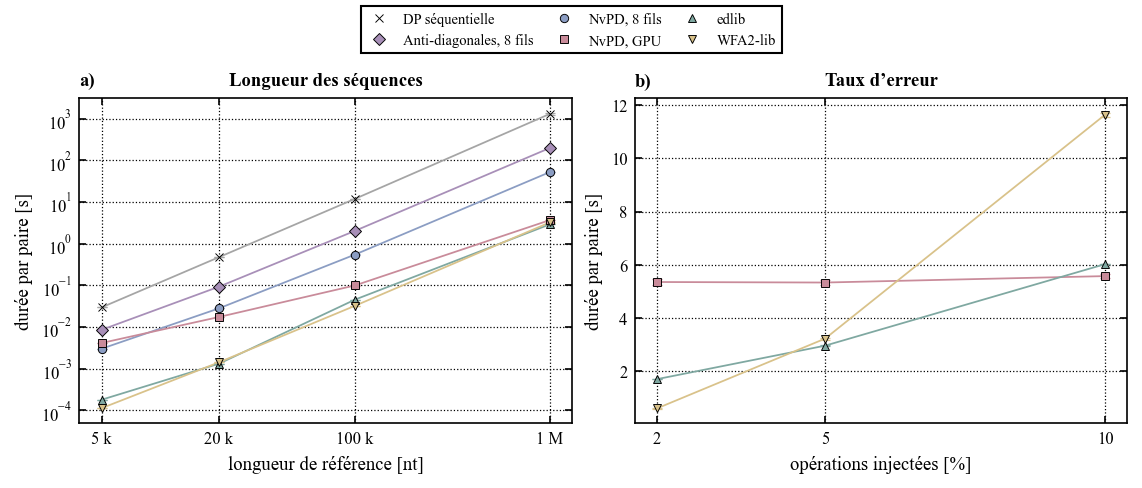

In [2]:
# Durée selon la longueur et le taux d'erreur (results/romeo/{cpu,gpu}-*.csv).
nv_runs = pd.concat(
    [nv_csv(path) for path in sorted((RES / "romeo").glob("*-*.csv"))], ignore_index=True
)
assert nv_runs.status.eq("ok").all() and (nv_runs.seconds > 0).all()
assert nv_runs.groupby("input_sha256").distance.nunique().eq(1).all()
nv_methods = {
    "seq": ("DP séquentielle", COLORS[4], "x"),
    "diagonal": ("Anti-diagonales, 8 fils", COLORS[5], "D"),
    "nvpd-omp": ("NvPD, 8 fils", COLORS[0], "o"),
    "nvpd-cuda": ("NvPD, GPU", COLORS[1], "s"),
    "edlib": ("edlib", COLORS[2], "^"),
    "wfa2": ("WFA2-lib", COLORS[3], "v"),
}
nv_selected = nv_runs[nv_runs.threads.eq(8) | ~nv_runs.algorithm.isin(["diagonal", "nvpd-omp"])]
# Une seule valeur par paire et méthode, même quand une campagne répète sa mesure.
nv_pair = nv_selected.groupby(
    ["length", "rate", "rep", "algorithm", "input_sha256"], as_index=False
).agg(seconds=("seconds", "mean"), distance=("distance", "first"))
nv_fig, nv_ax = plt.subplots(1, 2, figsize=(7.5, 3.15))
nv_sizes = [5_000, 20_000, 100_000, 1_000_000]
nv_rates = [0.02, 0.05, 0.10]
nv_epyc = nv_csv(RES / "repeated/epyc/trials.csv")
nv_grace = nv_csv(RES / "repeated/gh200/trials.csv")
nv_hot = pd.concat(
    [nv_epyc[nv_epyc.warmup.eq(0)], nv_grace[nv_grace.warmup.eq(0) & nv_grace.algorithm.eq("nvpd-cuda")]]
)
nv_dense = nv_csv(RES / "repeated/epyc-scalar/trials.csv")
assert nv_dense.algorithm.eq("seq").all()
nv_hot = pd.concat([nv_hot, nv_dense[nv_dense.warmup.eq(0)]], ignore_index=True)
nv_hot = nv_hot[nv_hot.case.str.startswith("syn-")].copy()
nv_hot["length"] = nv_hot.case.str.split("-").str[1].astype(int)
nv_hot["rate"] = nv_hot.case.str.rsplit("-", n=1).str[-1].astype(float)
assert nv_hot.groupby("case").input_sha256.nunique().eq(1).all()
assert nv_hot.groupby("case").distance.nunique().eq(1).all()
for nv_alg, (nv_name, nv_color, nv_marker) in nv_methods.items():
    nv_key = "nvpd-simd" if nv_alg == "nvpd-omp" else nv_alg
    nv_size = nv_hot[nv_hot.algorithm.eq(nv_key) & nv_hot.rate.eq(0.05)].set_index("length").seconds
    nv_counts = nv_size.groupby(level=0).size().reindex(nv_sizes)
    if nv_counts.tolist() != [9, 9, 5, 5]:
        raise ValueError(f"Effectif incomplet pour {nv_name} à 5 % : {nv_counts.to_dict()}")
    nv_plot(
        nv_ax[0],
        nv_size,
        nv_sizes,
        nv_sizes,
        1,
        "seconds_5pct",
        nv_key,
        "fresh_warmed_process",
        nv_color,
        nv_marker,
        joined=True,
        label=nv_name,
    )
    if nv_alg in ("nvpd-cuda", "edlib", "wfa2"):
        nv_err = (
            nv_pair[nv_pair.algorithm.eq(nv_alg) & nv_pair.length.eq(1_000_000)]
            .set_index("rate")
            .seconds
        )
        nv_plot(
            nv_ax[1],
            nv_err,
            nv_rates,
            [2, 5, 10],
            1,
            "seconds_1M",
            nv_alg,
            "independent_fasta_pair",
            nv_color,
            nv_marker,
            joined=True,
            label=nv_name,
        )
nv_ax[0].set(
    xscale="log", yscale="log", xlabel="longueur de référence [nt]", ylabel="durée par paire [s]"
)
nv_ax[0].set_xticks(nv_sizes, ["5 k", "20 k", "100 k", "1 M"])
nv_ax[1].set(xlabel="opérations injectées [%]", ylabel="durée par paire [s]")
nv_ax[1].set_xticks([2, 5, 10])
# Le débit dense utilise les dimensions effectives et le temps de chaque processus.
nv_dense_gpu = nv_csv(RES / "repeated/gh200/trials.csv")
nv_dense_gpu = nv_dense_gpu[
    nv_dense_gpu.warmup.eq(0)
    & nv_dense_gpu.algorithm.eq("nvpd-cuda")
    & nv_dense_gpu.case.str.startswith("syn-1000000-")
]
for nv_case, nv_gpu_case in nv_dense_gpu.groupby("case"):
    nv_gcups = nv_gpu_case.m * nv_gpu_case.n / (1e9 * nv_gpu_case.seconds)
    nv_stats.add(1, "gcups", "nvpd-cuda", nv_case, nv_gcups, "fresh_warmed_process")
label_panels(nv_ax)
column_titles(nv_ax, ("Longueur des séquences", "Taux d’erreur"))
legend_above(nv_fig, nv_ax, ncol=3)
nv_save(nv_fig, "comparison/temps_distance")

*Figure 1.* Le panneau a) mesure le deuxième appel de processus indépendants sur la première paire de chaque longueur à 5 %, après une chauffe identique. Les méthodes CPU tournent sur EPYC, CUDA sur GH200. À un million de bases, les cinq processus scalaires par taux tournent simultanément sur des cœurs distincts d’une autre allocation EPYC. Leur dispersion inclut les différences entre cœurs à cet instant, sans appariement aux autres méthodes. Le panneau b) décrit une autre campagne, menée à froid sur cinq paires différentes par taux. Son IC traduit la variabilité entre entrées.

<sub>Code : [scripts/datasets/synthetic.py](../scripts/datasets/synthetic.py), [src/libraries/baselines.cpp](../src/libraries/baselines.cpp), [bench/campaign/run.py](../bench/campaign/run.py), [results/romeo](../results/romeo/), [results/repeated/epyc/trials.csv](../results/repeated/epyc/trials.csv), [results/repeated/gh200/trials.csv](../results/repeated/gh200/trials.csv), [results/repeated/epyc-scalar/trials.csv](../results/repeated/epyc-scalar/trials.csv), [results/repeated/epyc-scalar/placement.csv](../results/repeated/epyc-scalar/placement.csv).</sub>

Les méthodes denses calculent toutes les cases, y compris à faible distance. Les méthodes par bits et par fronts visitent ou représentent moins d’états. L’écart se voit sur les cinq paires d’un million de bases. À froid à 2 %, WFA2-lib demande en moyenne 0,610 (écart-type 0,009, IC 95 % de 0,599 à 0,621) s. Son coût augmente avec le taux injecté. Sur la première paire à 5 % après chauffe, NvPD CUDA traite 273,2 (écart-type 1,1, IC 95 % de 271,9 à 274,5) milliards de cases par seconde. Le calcul divise le nombre réel de cases par le temps de chaque processus.

Sur la première paire à 5 %, le calcul scalaire prend 1291,9 s en moyenne. Les demi-largeurs relatives des IC du scalaire vont de 7,7 à 8,1 % selon le taux. Les deux groupes de cœurs occupés simultanément ont des durées distinctes et leurs proportions varient avec le taux. La version NvPD vectorisée à huit cœurs prend 51,9 s sur cette entrée dans une réservation distincte.

Le coût des méthodes denses conduit à examiner la répartition des colonnes entre les cœurs.

<p><strong><u>Synthèse.</u></strong> À 1 Mnt, la méthode la plus rapide sur ces machines dépend du taux injecté.<br>La programmation dynamique dense offre une comparaison à volume de travail connu.</p>

<a id="echelle-openmp"></a>

## Passage à l’échelle sur un processeur

<hr>

La figure 2 suit l’évolution du temps lorsque les fils OpenMP se partagent les colonnes d’une matrice.

Soit $T_p(m,n)$ le temps d’un essai de NvPD sur $p$ cœurs. À taille fixe, l’accélération vaut $S_p=T_1(m,n)/T_p(m,n)$, l’efficacité $S_p/p$. À travail fixe par cœur, le calcul garde 4 096 lignes et multiplie le nombre de colonnes par $p$. L’efficacité faible vaut alors $T_1(4096,4096)/T_p(4096,4096p)$. Les deux expériences gardent le même nombre de barrières de lignes lorsque $p$ varie, mais seule la seconde conserve le nombre de cases à traiter par cœur. [Cornell, mesures de passage à l’échelle](https://cvw.cac.cornell.edu/parallel/efficiency/scaling) · [Amdahl, 1967](https://doi.org/10.1145/1465482.1465560)

Les essais emploient la même variante à l’intérieur de chaque courbe, des fils attachés aux cœurs avec OpenMP et une phase de chauffe. Chaque processus vérifie sa distance et l’empreinte de ses entrées contre la référence avant la mise en commun des résultats. V1 utilise un index d’entiers sur quatre octets et une boucle vectorisable. V2 essaie de représenter les écarts de l’index sur un octet.

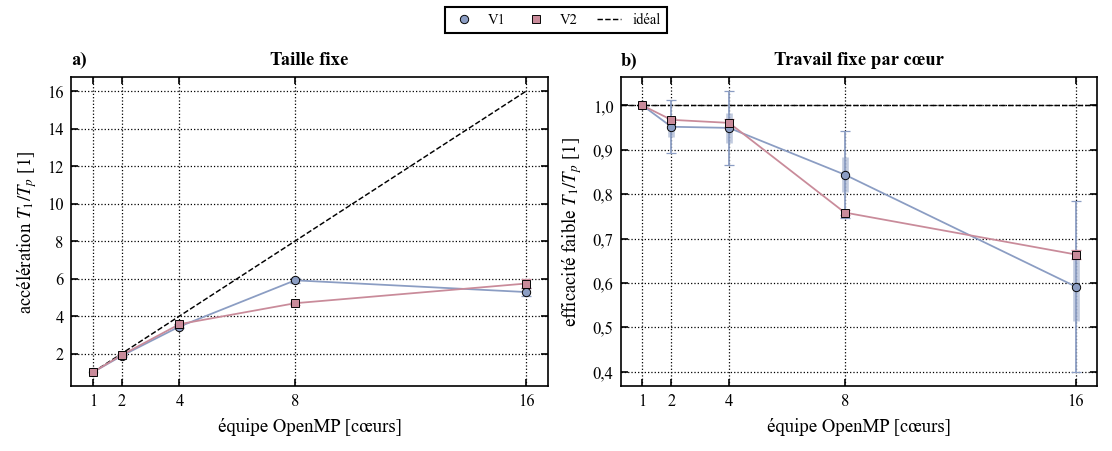

In [3]:
# Taille fixe et travail fixe par cœur, pour V1 et V2 (results/profile/cpu/scaling.csv).
sc_raw = nv_csv(PROF / "cpu/scaling.csv")
assert sc_raw.distance.eq(sc_raw.reference_distance).all()
sc_p = [1, 2, 4, 8, 16]
assert set(sc_raw.threads) == set(sc_p)
assert sc_raw.groupby(["variant", "study", "threads"]).trial.nunique().eq(3).all()
sc_fig, sc_ax = plt.subplots(1, 2, figsize=(7.3, 2.9))
for sc_i, sc_variant in enumerate(["v1", "v2"]):
    for sc_j, sc_study in enumerate(["strong", "weak"]):
        sc_table = sc_raw[sc_raw.variant.eq(sc_variant) & sc_raw.study.eq(sc_study)]
        sc_blocks = sc_table.pivot(index="trial", columns="threads", values="seconds")
        sc_relative = sc_blocks.rdiv(sc_blocks[1], axis=0)
        sc_values = sc_relative.rename_axis(columns="threads").stack().droplevel("trial")
        nv_plot(
            sc_ax[sc_j],
            sc_values,
            sc_p,
            sc_p,
            2,
            sc_study,
            sc_variant,
            "randomized_block",
            COLORS[sc_i],
            marker="os"[sc_i],
            joined=True,
            label=sc_variant.upper(),
        )
sc_ax[0].plot(sc_p, sc_p, **GUIDE, label="idéal")
sc_ax[0].set(xlabel="équipe OpenMP [cœurs]", ylabel=r"accélération $T_1/T_p$ [1]")
sc_ax[1].axhline(1, **GUIDE, label="idéal")
sc_ax[1].set(xlabel="équipe OpenMP [cœurs]", ylabel=r"efficacité faible $T_1/T_p$ [1]")
for sc_axis in sc_ax:
    sc_axis.set_xticks(sc_p)
label_panels(sc_ax)
column_titles(sc_ax, ("Taille fixe", "Travail fixe par cœur"))
legend_above(sc_fig, sc_ax, ncol=3)
nv_save(sc_fig, "cpu/echelle_cpu")

*Figure 2.* Chaque série utilise les rapports entre processus du même bloc aléatoire. Trois blocs ont chacun une chauffe complète par configuration. La diagonale indique l’accélération idéale à taille fixe. La droite horizontale indique l’efficacité idéale à charge fixe par cœur.

<sub>Code : [bench/cpu/openmp/profile_cpu_driver.cpp](../bench/cpu/openmp/profile_cpu_driver.cpp), [bench/cpu/openmp/profile_cpu.py](../bench/cpu/openmp/profile_cpu.py), [bench/cpu/openmp/profile_cpu.sbatch](../bench/cpu/openmp/profile_cpu.sbatch), [results/profile/cpu/scaling.csv](../results/profile/cpu/scaling.csv).</sub>

Sur le carré de 20 000 bases, le rapport apparié de V1 sur huit cœurs vaut 5,91 (écart-type 0,05, IC 95 % de 5,79 à 6,03). À seize cœurs, il vaut 5,28. La synchronisation de chaque ligne et l’accès partagé aux données continuent à peser lorsque chaque fil reçoit moins de colonnes.

Un million de colonnes permet d’observer cet effet sur des paires distinctes.

<p><strong><u>Synthèse.</u></strong> Sur seize cœurs, l’efficacité faible de V1 vaut 0,592.<br>Le calcul garde un nombre de cases par cœur constant, mais ses lignes deviennent plus longues.</p>

<a id="openmp-long"></a>

## Anti-diagonales et lignes de grande largeur

<hr>

La figure 3 compare deux parcours d’une même matrice sur les longues paires avec une équipe de huit cœurs.

Pour chaque FASTA, on calcule $S=T_{\rm diag}/T_{\rm NvPD}$ à partir d’un appel de chaque méthode. Le parcours des deux premières séries provient de la révision initiale f08b4f6. Le temps inclut la construction des tableaux et le calcul du coût après lecture du FASTA.

Le plan homogène comprend cinq paires à chaque taux, trois taux et deux méthodes. Une réplique désigne un nouveau tirage de séquences. Les six anciens témoins portant le numéro de réplique 1 restent dans les archives initiales. Les deux bibliothèques exactes vérifient toutes les distances. Une seconde campagne isole la vectorisation sur la première paire de chaque taux. Le gain du panneau b) vaut $T_{\rm initial}/T_{\rm SIMD}$. Les deux versions utilisent -O3 -march=native -fopenmp et les mêmes huit cœurs. Les blocs indépendants alternent l’ordre des versions. Chaque processus chauffe sur la paire complète avant l’appel chronométré.

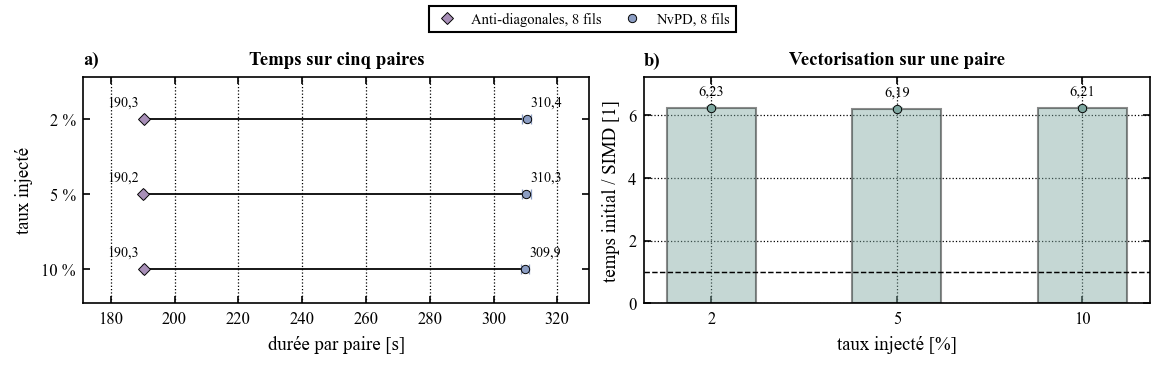

In [4]:
# Essais homogènes à un million de bases, une durée par méthode et par entrée.
long_raw = nv_csv(RES / "romeo/completion-1m/trials.csv")
assert len(long_raw) == 30 and long_raw.threads.eq(8).all() and long_raw.length.eq(1_000_000).all()
assert set(long_raw.algorithm) == {"diagonal", "nvpd-omp"}
assert long_raw.groupby(["rate", "algorithm"]).input_sha256.nunique().eq(5).all()
assert long_raw.groupby("input_sha256").distance.nunique().eq(1).all()
long_ref = nv_csv(RES / "romeo/completion-1m/references.csv")
assert set(long_ref.algorithm) == {"edlib", "wfa2"}
long_all = pd.concat([long_raw, long_ref])
assert long_all.groupby("input_sha256").algorithm.nunique().eq(4).all()
assert long_all.groupby("input_sha256").distance.nunique().eq(1).all()
long_times = long_raw.pivot(index=["rate", "input_sha256"], columns="algorithm", values="seconds")
long_ratio = long_times.diagonal / long_times["nvpd-omp"]
long_fig, long_ax = plt.subplots(1, 2, figsize=(7.65, 2.35))
long_rates = [0.02, 0.05, 0.10]
for long_i, long_rate in enumerate(long_rates):
    long_entries = []
    for long_alg in ["diagonal", "nvpd-omp"]:
        long_lab, long_col, long_mark = nv_methods[long_alg]
        long_values = long_times.xs(long_rate)[long_alg]
        long_entry = nv_stats.add(
            3, "seconds", long_alg, long_rate, long_values, "independent_fasta_pair"
        )
        long_entries.append((long_entry, long_col, long_mark, long_lab))
    comparison(long_ax[0], long_i, long_entries, digits=1)
category_rows(long_ax[0], ["2 %", "5 %", "10 %"], "durée par paire [s]")
long_blocks = nv_csv(RES / "repeated/epyc/trials.csv")
long_selected = long_blocks[
    long_blocks.warmup.eq(0)
    & long_blocks.algorithm.isin(["nvpd-initial", "nvpd-simd"])
    & long_blocks["case"].str.startswith("syn-1000000-")
]
long_matrix = long_selected.pivot(index=["case", "block"], columns="algorithm", values="seconds")
if (
    len(long_matrix) != 15
    or not long_selected.groupby(["case", "algorithm"]).block.nunique().eq(5).all()
):
    raise ValueError("La comparaison SIMD exige cinq blocs appariés sur trois entrées.")
assert long_matrix.notna().all().all() and long_selected.groupby("case").distance.nunique().eq(1).all()
long_gains = (long_matrix["nvpd-initial"] / long_matrix["nvpd-simd"]).droplevel("block")
long_gains.index = long_gains.index.str.rsplit("-", n=1).str[-1].astype(float)
for long_x, long_rate in enumerate(long_rates):
    long_stats = nv_stats.add(
        3,
        "speedup",
        "initial/SIMD",
        long_rate,
        long_gains[long_gains.index == long_rate],
        "paired_process_block",
    )
    long_ax[1].bar(long_x, long_stats["mean"], width=0.48, color=COLORS[2], alpha=0.45, edgecolor=INK)
    estimate(long_ax[1], long_x, long_stats, COLORS[2])
    value_label(long_ax[1], long_x, long_stats["high95"], long_stats["mean"], 2)
long_ax[1].axhline(1, **GUIDE)
long_ax[0].set_ylabel("taux injecté")
long_ax[1].set(
    xticks=range(3),
    xticklabels=["2", "5", "10"],
    xlabel="taux injecté [%]",
    ylabel="temps initial / SIMD [1]",
)
long_ax[1].margins(y=0.15)
long_ax[1].set_ylim(bottom=0)
label_panels(long_ax)
column_titles(long_ax, ("Temps sur cinq paires", "Vectorisation sur une paire"))
legend_above(long_fig, long_ax, ncol=3)
nv_save(long_fig, "cpu/openmp_un_million")

*Figure 3.* À gauche, la campagne historique chronomètre une fois chacune de cinq paires indépendantes par taux. À droite, la campagne EPYC répète les deux versions sur la première paire de chaque taux dans cinq blocs de processus préchauffés. L’IC porte sur les rapports entre les deux durées d’un bloc.

<sub>Code : [bench/cpu/openmp/million/collect_1m.py](../bench/cpu/openmp/million/collect_1m.py), [results/romeo/completion-1m/trials.csv](../results/romeo/completion-1m/trials.csv), [results/romeo/completion-1m/references.csv](../results/romeo/completion-1m/references.csv), [bench/repeated/measure.py](../bench/repeated/measure.py), [results/repeated/epyc/trials.csv](../results/repeated/epyc/trials.csv).</sub>

À 2 %, les cinq paires demandent en moyenne 190,28 (écart-type 0,13, IC 95 % de 190,13 à 190,44) s par anti-diagonales. Pour les mêmes entrées, le temps moyen de NvPD initial vaut 310,37 s. À 5 %, le rapport apparié initial/SIMD vaut 6,19 (écart-type 0,04, IC 95 % de 6,14 à 6,24). Les cinq tirages historiques renseignent la variabilité entre entrées dans cette campagne.

La réécriture de la boucle de NvPD permet ensuite d’isoler le rôle du compilateur.

<p><strong><u>Synthèse.</u></strong> Les anti-diagonales terminent avant la version initiale sur les 15 paires mesurées.<br>La seconde comparaison isole la réécriture SIMD à compilation identique.</p>

<a id="vectorisation"></a>

## Vectorisation de la récurrence de dernière occurrence

<hr>

La figure 4 isole les gains successifs de la vectorisation de la récurrence et de la compression de son index.

La version initiale utilise la dernière occurrence $k$ d’une lettre pour choisir le prédécesseur. Pour la case $(i,j)$, $k$ est la dernière position de la lettre $a_i$ dans $b_1,\dots,b_j$ et vaut zéro si elle est absente. Sur les colonnes intérieures, V1 calcule

$$D_{i,j}=\min\!\left(1+\min(D_{i-1,j-1},D_{i-1,j}),\,D_{i-1,\max(0,k-1)}+j-k\right).$$

Les bords valent $D_{i,0}=i$ et $D_{0,j}=j$. La formule lit uniquement la ligne précédente. Quand $k=j$, le second candidat reprend la diagonale sans coût. Quand $k=0$, il vaut $i-1+j$, une borne supérieure de la distance. Cette forme permet à OpenMP de vectoriser les colonnes. V2 reprend cette boucle et stocke les écarts $j-k$ sur un octet lorsque le maximum reste inférieur à 256. Si un écart est plus grand, V2 garde les entiers de quatre octets. Les scores restent entiers dans les trois versions. Les appels NvPD incluent la construction de l’index de dernières occurrences, l’allocation et les mises à jour de la matrice. Chaque paire de variantes utilise la même compilation, avec `-O3 -march=native -fopenmp`. À chaque répétition, le pilote mélange l’ordre des cas et alterne A puis B ou B puis A.

Les trois géométries isolent deux effets. Le carré de 20 000 × 20 000 distribue de nombreuses lignes de taille modérée. Les rectangles de 256 × 1 000 000 et de 64 × 4 194 304 contiennent des lignes de plus en plus longues et peu de barrières. Le second rectangle donne à l’index une largeur de plus de quatre millions de colonnes pour étudier son comportement dans les caches.

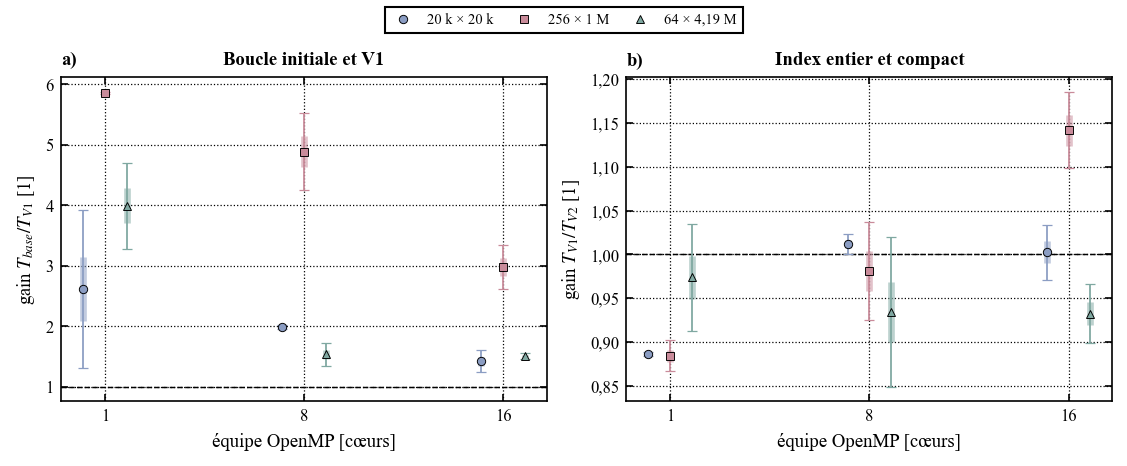

In [5]:
# Gains par étape à entrées et placement identiques (results/profile/cpu/ab.csv).
ab_raw = nv_csv(PROF / "cpu/ab.csv")
assert ab_raw.distance.eq(ab_raw.reference_distance).all()
assert ab_raw.groupby("case").input_fnv64.nunique().eq(1).all()
assert ab_raw.groupby(["comparison", "case", "threads", "trial"]).cpu_ids.nunique().eq(1).all()
assert ab_raw.groupby("case").max_gap.max().lt(256).all()
ab_cases = {"square": "20 k × 20 k", "wide": "256 × 1 M", "over_l3": "64 × 4,19 M"}
# Expérience distincte, une paire de mesures par taux à un million de bases.
ab_long = nv_csv(RES / "profile/million/838538/trials.csv")
assert len(ab_long) == 6 and set(ab_long.variant) == {"initial", "simd"}
assert ab_long.groupby("rate").input_sha256.nunique().eq(1).all()
assert ab_long.groupby("rate").distance.nunique().eq(1).all()
assert ab_long.groupby("rate").cpu_ids.nunique().eq(1).all()
ab_long_ref = (
    nv_pair[nv_pair.algorithm.eq("edlib") & nv_pair.rep.eq(1) & nv_pair.length.eq(1_000_000)]
    .set_index("input_sha256")
    .distance
)
assert ab_long.distance.eq(ab_long.input_sha256.map(ab_long_ref)).all()
ab_long_seconds = ab_long.pivot(index="rate", columns="variant", values="seconds")
ab_long_gains = ab_long_seconds.initial / ab_long_seconds.simd

ab_fig, ab_ax = plt.subplots(1, 2, figsize=(7.4, 3.0))
for ab_i, (ab_a, ab_b) in enumerate([("baseline", "v1"), ("v1", "v2")]):
    ab_data = ab_raw[ab_raw.comparison.eq(ab_a + "-" + ab_b)]
    ab_time = ab_data.pivot(index=["case", "threads", "trial"], columns="variant", values="seconds")
    ab_ratio = ab_time[ab_a] / ab_time[ab_b]
    for ab_k, (ab_case, ab_name) in enumerate(ab_cases.items()):
        ab_series = ab_ratio.xs(ab_case).droplevel("trial")
        nv_plot(
            ab_ax[ab_i],
            ab_series,
            [1, 8, 16],
            np.arange(3) + (ab_k - 1) * 0.11,
            4,
            ab_a + "/" + ab_b,
            ab_case,
            "paired_process_block",
            COLORS[ab_k],
            "os^"[ab_k],
            label=ab_name,
        )
    ab_ax[ab_i].axhline(1, **GUIDE)
    ab_ax[ab_i].set(xticks=range(3), xticklabels=["1", "8", "16"], xlabel="équipe OpenMP [cœurs]")
ab_ax[0].set_ylabel(r"gain $T_{base}/T_{V1}$ [1]")
ab_ax[1].set_ylabel(r"gain $T_{V1}/T_{V2}$ [1]")
label_panels(ab_ax)
column_titles(ab_ax, ("Boucle initiale et V1", "Index entier et compact"))
legend_above(ab_fig, ab_ax, ncol=3)
nv_save(ab_fig, "cpu/variantes_cpu")

*Figure 4.* Les rapports se calculent à forme, placement et bloc identiques avant de prendre la moyenne. Pour chaque point, trois processus indépendants par version ont exécuté un alignement de chauffe, suivi de l’alignement mesuré.

<sub>Code : [src/cpu/dp.cpp](../src/cpu/dp.cpp), [bench/cpu/openmp/profile_cpu.md](../bench/cpu/openmp/profile_cpu.md), [bench/cpu/openmp/profile_cpu.py](../bench/cpu/openmp/profile_cpu.py), [results/profile/cpu/ab.csv](../results/profile/cpu/ab.csv), [results/profile/million/838538/trials.csv](../results/profile/million/838538/trials.csv).</sub>

Sur le carré de 20 000 bases à huit cœurs, le gain initial/V1 vaut 1,99 (écart-type 0,01, IC 95 % de 1,96 à 2,02). Pour V2, la conversion de l’index en octets ajoute du travail avant la récurrence. Le gain V1/V2 du grand rectangle sur les mêmes huit cœurs vaut 0,93.

Les compteurs de cache permettent de comparer les lectures avec les tailles allouées.

<p><strong><u>Synthèse.</u></strong> Les deux transformations ont des effets différents sur les neuf couples forme et équipe.<br>La récurrence vectorisée conserve l’index entier dans la version de production.</p>

<a id="hierarchie-memoire"></a>

## Occupation mémoire et défauts du cache de données

<hr>

La figure 5 compare l’espace occupé par les tableaux et le nombre de défauts de lecture L1D selon la largeur de la matrice.

Pour un alphabet de quatre lettres, les deux lignes de scores occupent $2(n+1)$ entiers. L’index des dernières occurrences en occupe $4(n+1)$. V1 occupe donc $24(n+1)$ octets. Si la conversion réussit, V2 occupe $12(n+1)$ octets pendant la boucle. La conversion conserve temporairement deux représentations de l’index. Une ligne lue pour une lettre donnée ne consulte qu’une des quatre lignes de cet index. Le pic RSS mesure le maximum de mémoire résidente du processus entier, y compris les chaînes, les autres allocations et la phase de chauffe.

Les compteurs en espace utilisateur couvrent un appel après chauffe, pour toute l’équipe OpenMP. Le pilote ouvre et ferme la fenêtre de mesure avec `perf stat --control`. Un compteur non pris en charge représente une mesure manquante. Les événements génériques dépendent du PMU et ne suffisent pas à déduire un débit DRAM. Les écarts maximaux, de 31 à 48 selon la forme, permettent à V2 d’utiliser des octets sur les trois cas. [Linux perf, manuel de perf-stat](https://man7.org/linux/man-pages/man1/perf-stat.1.html)

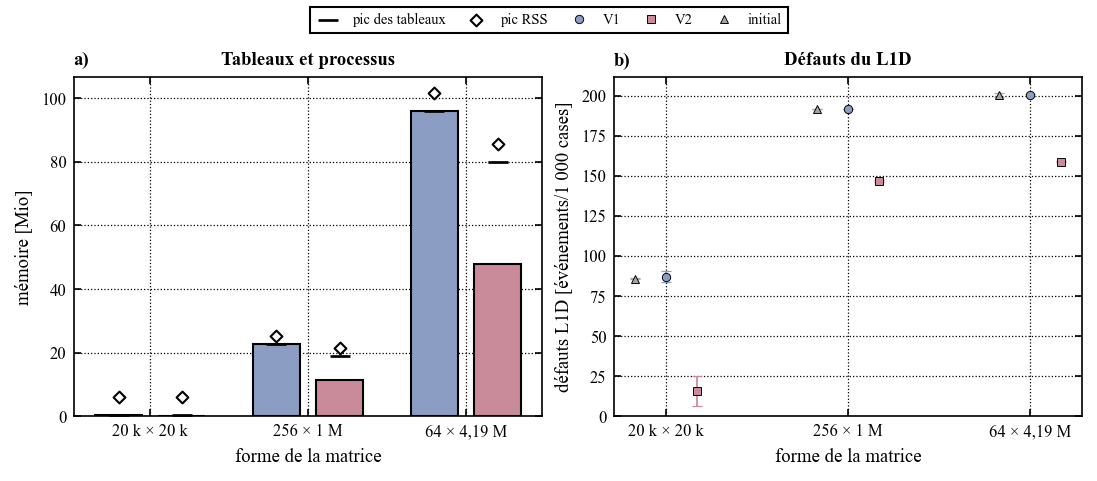

In [6]:
# Espace de travail et événements L1D, huit cœurs (results/profile/cpu/{ab,counters}.csv).
me_perf = nv_csv(PROF / "cpu/counters.csv")
assert me_perf.distance.eq(me_perf.reference_distance).all()
assert me_perf.running_pct.eq(100).all()
me_perf["event"] = me_perf.event.str.removesuffix(":u")
me_perf["count"] = pd.to_numeric(me_perf.value, errors="coerce")
me_perf["per_cell"] = me_perf["count"] / (me_perf.m * me_perf.n)
me_fig, me_ax = plt.subplots(1, 2, figsize=(7.2, 3.1))
me_x = np.arange(len(ab_cases))
me_rows = ab_raw[(ab_raw.threads == 8) & ab_raw.comparison.eq("v1-v2")]
for me_i, me_v in enumerate(["v1", "v2"]):
    me_g = me_rows[me_rows.variant.eq(me_v)].groupby("case")
    me_scores = me_g.dp_bytes.first().reindex(ab_cases)
    me_index = me_g.mit_bytes.first().reindex(ab_cases)
    me_peak = me_g.workspace_peak_bytes.first().reindex(ab_cases)
    me_rss = me_g.peak_rss_kib.max().reindex(ab_cases) / 1024
    me_pos = me_x + 0.2 * (2 * me_i - 1)
    me_ax[0].bar(
        me_pos,
        (me_scores + me_index) / 2**20,
        width=0.30,
        color=COLORS[me_i],
        edgecolor=INK,
        label=me_v.upper(),
        zorder=2,
    )
    me_ax[0].scatter(
        me_pos,
        me_peak / 2**20,
        marker="_",
        s=100,
        color=INK,
        zorder=3,
        label="pic des tableaux" if me_i == 0 else None,
    )
    me_ax[0].scatter(
        me_pos,
        me_rss,
        marker="D",
        s=16,
        facecolor=PAPER,
        edgecolor=INK,
        zorder=3,
        label="pic RSS" if me_i == 0 else None,
    )
for me_k, me_v in enumerate(["baseline", "v1", "v2"]):
    me_g = me_perf[
        (me_perf.threads == 8) & me_perf.event.eq("L1-dcache-load-misses") & me_perf.variant.eq(me_v)
    ]
    me_series = me_g.set_index("case").per_cell * 1000
    nv_plot(
        me_ax[1],
        me_series,
        list(ab_cases),
        me_x + 0.17 * (me_k - 1),
        5,
        "l1d_misses_per_1000",
        me_v,
        "perf_process",
        [COLORS[4], COLORS[0], COLORS[1]][me_k],
        "^os"[me_k],
        label=me_v.upper() if me_v != "baseline" else "initial",
    )
me_ax[0].set(ylabel="mémoire [Mio]", xlabel="forme de la matrice")
me_ax[1].set(ylabel="défauts L1D [événements/1 000 cases]", xlabel="forme de la matrice", ylim=(0, None))
for me_axis in me_ax:
    me_axis.set_xticks(me_x, ab_cases.values())
label_panels(me_ax)
column_titles(me_ax, ("Tableaux et processus", "Défauts du L1D"))
legend_above(me_fig, me_ax, ncol=5)
nv_save(me_fig, "cpu/memoire_cpu")

*Figure 5.* À gauche, les barres donnent les tableaux actifs, le tiret leur maximum transitoire et le losange le plus grand RSS observé. À droite, deux processus perf par configuration comptent les défauts après une chauffe. Avec deux observations, l’IC de la moyenne peut être large.

<sub>Code : [bench/cpu/openmp/profile_cpu_driver.cpp](../bench/cpu/openmp/profile_cpu_driver.cpp), [bench/cpu/openmp/profile_cpu.py](../bench/cpu/openmp/profile_cpu.py), [results/profile/cpu/environment.txt](../results/profile/cpu/environment.txt), [results/profile/cpu/counters.csv](../results/profile/cpu/counters.csv).</sub>

La conversion atteint 80 Mio et le processus monte à 85,5 Mio, contre 101,6 Mio en V1. Sur huit cœurs, on compte 159 défauts L1D pour 1 000 cases en V2, contre 200 en V1, alors que le rapport moyen de temps V1/V2 vaut 0,93. Le nœud dispose de 32 Kio de L1D et 1 Mio de L2 par cœur, ainsi que de blocs de 32 Mio de L3 partagés par huit cœurs. Le plus grand index dépasse la capacité d’un de ces blocs.

Le nombre d’instructions par case renseigne sur les autres coûts de la boucle.

<p><strong><u>Synthèse.</u></strong> Sur le rectangle de 4 194 304 colonnes, l’index compact ramène les tableaux actifs de 96 à 48 Mio.<br>Les compteurs L1D décrivent les lectures du cache. Ils ne donnent pas le débit du contrôleur DRAM.</p>

<a id="trace-lineaire"></a>

## Reconstruction de l’alignement en espace linéaire

<hr>

La figure 6 compare le temps et le pic de mémoire du processus pour retrouver un chemin optimal de deux manières.

Le procédé de Hirschberg a été publié pour la plus longue sous-séquence commune. Ici les deux passes utilisent les coûts de Levenshtein. À la coupure $i=\lfloor m/2\rfloor$, $F_j$ donne le coût entre les préfixes $a_{1:i}$ et $b_{1:j}$. Une passe sur les chaînes inversées donne les coûts de suffixe $R_{n-j}$. On choisit $j^\star\in\arg\min_j(F_j+R_{n-j})$ et on reconstruit les deux sous-chemins. Les passes calculent au total $O(mn)$ cases et utilisent $O(\min(m,n))$ scores en choisissant la chaîne la plus courte pour les colonnes. Cette borne exclut la pile de récursion et le chemin en sortie. Le format CIGAR regroupe les longueurs successives de correspondances (=), substitutions (X), insertions (I) et suppressions (D). [Hirschberg, 1975](https://doi.org/10.1145/360825.360861)

Les mesures sur un cœur AMD EPYC 9654 de ROMEO lancent les algorithmes sur le même FASTA lorsqu’ils acceptent sa longueur. Le pilote exécute une seule méthode par processus. À chaque taille, 31 blocs indépendants chauffent chaque méthode sur la paire complète avant l’alignement chronométré. Les chemins et les scores sont vérifiés. Les cases de la figure représentent les configurations exécutées. L’implémentation qui conserve tout le tableau limite les deux longueurs à 20 000 bases pour le chemin.

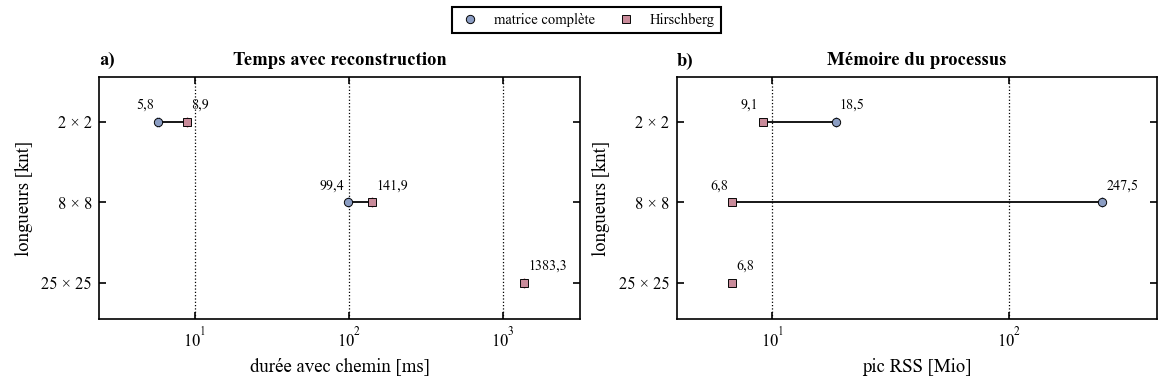

In [7]:
# Coût et mémoire d'une reconstruction complète ou par coupures.
tb_trials = nv_csv(RES / "repeated/epyc-trace/trials.csv")
tb_raw = tb_trials[tb_trials.warmup.eq(0)].rename(
    columns={"process_peak_rss_kib": "peak_rss_kib", "input_sha256": "sha256"}
)
assert tb_raw.groupby(["case", "algorithm"]).block.nunique().eq(31).all()
assert tb_raw.groupby("case").distance.nunique().eq(1).all()
assert tb_raw.groupby("case").sha256.nunique().eq(1).all()
tb_shapes = tb_raw[["case", "m", "n"]].drop_duplicates().sort_values(["m", "n"]).set_index("case")
tb_cases = list(tb_shapes.index)
tb_labels = [f"{tb_shapes.loc[c, 'm'] / 1000:g} × {tb_shapes.loc[c, 'n'] / 1000:g}" for c in tb_cases]
tb_alg_h = next(method for method in tb_raw.algorithm.unique() if "hirsch" in method.lower())
tb_alg_d = next(method for method in tb_raw.algorithm.unique() if method != tb_alg_h)
tb_fig, tb_ax = plt.subplots(1, 2, figsize=(7.7, 2.5))
for tb_i, tb_case in enumerate(tb_cases):
    for tb_j, (tb_measure, tb_factor, tb_unit, tb_digits) in enumerate(
        [("seconds", 1000, "milliseconds", 1), ("peak_rss_kib", 1 / 1024, "rss_mib", 1)]
    ):
        tb_entries = []
        for tb_k, (tb_alg, tb_label) in enumerate(
            [(tb_alg_d, "matrice complète"), (tb_alg_h, "Hirschberg")]
        ):
            tb_rows = tb_raw[tb_raw.case.eq(tb_case) & tb_raw.algorithm.eq(tb_alg)]
            if len(tb_rows):
                tb_obs = nv_stats.add(
                    6, tb_unit, tb_alg, tb_case, tb_rows[tb_measure] * tb_factor, "fresh_process"
                )
                tb_entries.append((tb_obs, COLORS[tb_k], "os"[tb_k], tb_label))
        comparison(tb_ax[tb_j], tb_i, tb_entries, digits=tb_digits)
for tb_axis, tb_xlabel in zip(tb_ax, ["durée avec chemin [ms]", "pic RSS [Mio]"]):
    tb_axis.set_xscale("log")
    category_rows(tb_axis, tb_labels, tb_xlabel)
    tb_axis.set_ylabel("longueurs [knt]")
label_panels(tb_ax)
column_titles(tb_ax, ("Temps avec reconstruction", "Mémoire du processus"))
legend_above(tb_fig, tb_ax, ncol=2)
nv_save(tb_fig, "cpu/trace_lineaire")

*Figure 6.* Chaque estimation provient de 31 processus indépendants sur un cœur EPYC. Un premier calcul complet avec chemin chauffe la même paire. Le deuxième fournit la durée et le pic RSS du processus inclut les deux appels. À 25 knt, seul Hirschberg est exécuté.

<sub>Code : [src/cpu/hirschberg.cpp](../src/cpu/hirschberg.cpp), [bench/repeated/kernel.cpp](../bench/repeated/kernel.cpp), [bench/repeated/measure.py](../bench/repeated/measure.py), [results/repeated/epyc-trace/trials.csv](../results/repeated/epyc-trace/trials.csv).</sub>

À 8 knt, le calcul Hirschberg demande 141,90 (écart-type 0,51, IC 95 % de 141,71 à 142,09) ms. Pour cette paire, le maintien de toute la matrice augmente la mémoire requise. Le pic RSS moyen à 8 knt atteint 247,48 Mio pour la matrice et 6,78 Mio pour Hirschberg. Les coupures calculent plusieurs fois une partie des scores et échangent ce travail contre une réduction du pic RSS. Le chemin est vérifié en rejouant toutes ses opérations.

Les compteurs du processeur permettent ensuite d’examiner les instructions du calcul de coût.

<p><strong><u>Synthèse.</u></strong> La reconstruction par coupures restitue un chemin de coût 531 pour deux chaînes de 25 000 bases.<br>La politique de mémoire de la matrice complète borne les entrées qu’elle accepte.</p>

<a id="instructions"></a>

## Instructions et prédictions de branchement

<hr>

La figure 7 rapporte le travail exécuté par le processeur au nombre de cases de la matrice.

Pour $N=mn$ cases, les événements par case valent $C/N$. Les compteurs proviennent de deux appels après chauffe et la fréquence d’horloge peut varier.

L’IPC rapporte les instructions retirées aux cycles comptés. Un événement de branchement mal prédit concerne le chemin d’exécution du processeur. Sur une équipe, les cycles comptés s’additionnent sur les fils. Les données de cette figure proviennent d’un seul cœur.

Linux perf recueille les événements matériels via les compteurs de l’unité de suivi des performances. Le pilote limite le comptage à la région NvPD après chauffe. [Linux, perf stat](https://man7.org/linux/man-pages/man1/perf-stat.1.html)

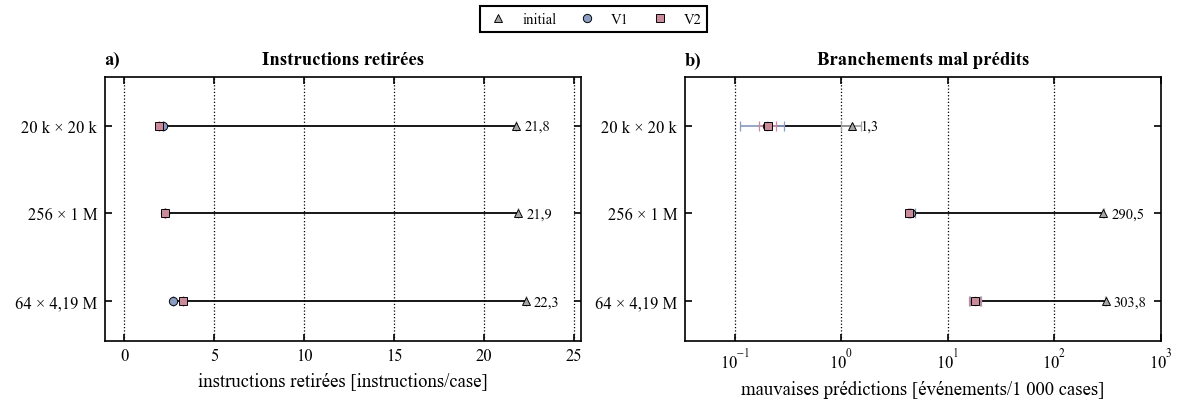

In [8]:
# Compteurs du calcul à un cœur. La valeur disponible est ramenée à une case.
pm_g = me_perf[me_perf.threads.eq(1)]
pm_fig, pm_ax = plt.subplots(1, 2, figsize=(7.8, 2.65))
pm_events = [
    ("instructions", 1, "instructions retirées [instructions/case]"),
    ("branch-misses", 1000, "mauvaises prédictions [événements/1 000 cases]"),
]
for pm_i, (pm_event, pm_scale, pm_label) in enumerate(pm_events):
    for pm_j, (pm_case, pm_name) in enumerate(ab_cases.items()):
        pm_entries = []
        for pm_k, (pm_var, pm_legend) in enumerate(
            [("baseline", "initial"), ("v1", "V1"), ("v2", "V2")]
        ):
            pm_series = (
                pm_g[pm_g.event.eq(pm_event) & pm_g.variant.eq(pm_var) & pm_g.case.eq(pm_case)].per_cell
                * pm_scale
            )
            pm_rec = nv_stats.add(7, pm_event, pm_var, pm_case, pm_series, "perf_process")
            pm_entries.append((pm_rec, [COLORS[4], COLORS[0], COLORS[1]][pm_k], "^os"[pm_k], pm_legend))
        comparison(pm_ax[pm_i], pm_j, pm_entries, annotate=False)
        pm_end = pm_entries[0][0]["mean"]
        value_label(pm_ax[pm_i], pm_end, pm_j, pm_end, 1, horizontal=True)
    if pm_i == 1:
        pm_ax[pm_i].set_xscale("log")
    category_rows(pm_ax[pm_i], list(ab_cases.values()), pm_label)
label_panels(pm_ax)
column_titles(pm_ax, ("Instructions retirées", "Branchements mal prédits"))
legend_above(pm_fig, pm_ax, ncol=3)
nv_save(pm_fig, "cpu/cout_instructions")

*Figure 7.* Deux processus indépendants et préchauffés fournissent les compteurs par forme et variante. Le panneau a) rapporte les instructions à une case, le panneau b) les erreurs de prédiction à mille cases.

<sub>Code : [src/cpu/dp.cpp](../src/cpu/dp.cpp), [bench/cpu/openmp/profile_cpu.py](../bench/cpu/openmp/profile_cpu.py), [results/profile/cpu/vectorization.csv](../results/profile/cpu/vectorization.csv), [results/profile/cpu/counters.csv](../results/profile/cpu/counters.csv).</sub>

À un cœur sur le rectangle de 256 lignes, les instructions passent de 21,89 par case à 2,26 entre la version initiale et V1. Les mauvaises prédictions passent de 291 à 4,5 pour 1 000 cases et les cycles de 9,46 à 1,59 par case. Pour le carré, les mauvaises prédictions sont déjà rares dans la version initiale (1,3 pour 1 000 cases) et V1 réduit encore le nombre d’instructions de 21,76 à 2,13 par case. Le diagnostic de GCC confirme des vecteurs de 32 octets dans cette boucle.

Sur GPU, la même indépendance entre colonnes permet de regrouper plusieurs lignes.

<p><strong><u>Synthèse.</u></strong> Sur le grand rectangle à un cœur, la version vectorisée réduit les cycles par case d’un facteur 5,95.<br>Le coût de la prédiction se manifeste davantage sur ce rectangle que sur le carré.</p>

<a id="tuiles-cuda"></a>

## Regroupement des lignes en tuiles CUDA

<hr>

La figure 8 compare un noyau CUDA lancé à chaque ligne à un noyau qui regroupe plusieurs lignes.

Pour $q$ lignes par tuile et $m$ lignes, le noyau principal est lancé $\lceil m/q\rceil$ fois si la portée des dépendances permet ce découpage. Le gain divise les moyennes des deux versions entre processus. Chaque processus fournit une première durée puis la moyenne de trois appels chauds.

Dans la version initiale (A), le CPU lance un noyau par ligne. La variante retenue (B) avance de huit lignes par tuile en mémoire partagée. Chaque bloc recalcule un halo à gauche pour pouvoir progresser sans lire le travail d’un bloc voisin. Ses 256 fils couvrent 1 024 colonnes lorsque la grille garde au moins deux blocs par multiprocesseur, sinon 256. Lorsque la dépendance gauche dépasse 64 colonnes, ou que le chemin d’alignement est demandé, le programme utilise le noyau par ligne. La mesure à froid démarre dans un processus neuf. Les mesures à chaud démarrent après un premier appel vérifié dans ce même processus. Le retour du dernier coût sur l’hôte garantit que le GPU a terminé. Dans les deux cas, le temps couvre aussi le calcul de l’index, les allocations et les transferts. [NVIDIA, mesure du temps CPU et GPU](https://docs.nvidia.com/cuda/cuda-c-best-practices-guide/index.html#timing)

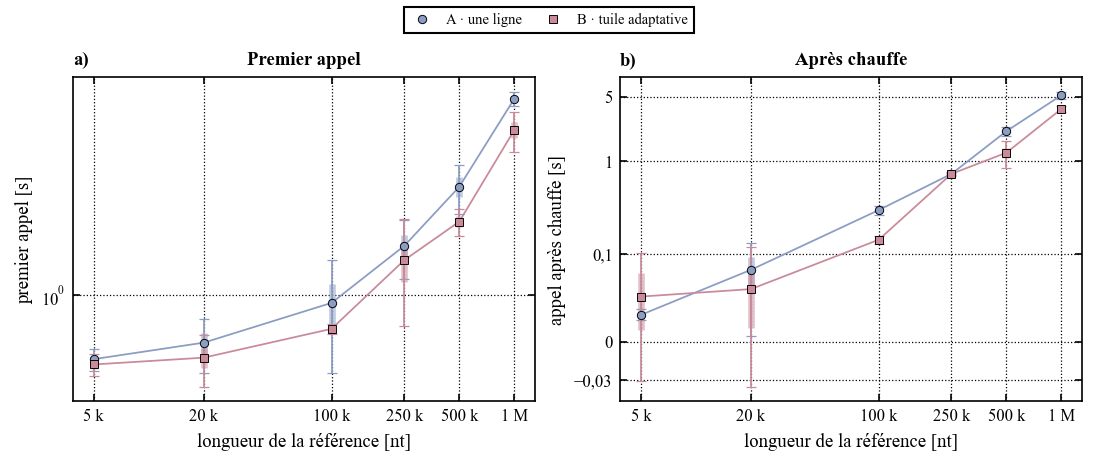

In [9]:
# Appels froids et chauds sur les mêmes FASTA, hors capture Nsight.
gp_dir = PROF / "gpu/838170"
gp_raw = nv_csv(gp_dir / "trials.csv")
gp_truth = nv_pair[nv_pair.algorithm.eq("edlib") & nv_pair.rate.eq(0.02) & nv_pair.rep.eq(1)]
assert set(gp_raw.variant) == {"baseline", "candidate"} and gp_raw.trace.eq(0).all()
gp_ref = gp_truth.set_index("length").distance
assert gp_raw.groupby("input").distance.nunique().eq(1).all()
gp_comparable = gp_raw[gp_raw.m.isin(gp_ref.index)]
assert gp_comparable.distance.eq(gp_comparable.m.map(gp_ref)).all()
assert gp_raw.groupby(["input", "variant", "mode"]).run.nunique().eq(3).all()
gp_counts = gp_raw.groupby(["input", "variant", "mode", "run"]).size()
assert gp_counts.xs("cold", level="mode").eq(1).all() and gp_counts.xs("warm", level="mode").eq(3).all()
assert gp_raw.groupby("input").device_bytes.nunique().eq(1).all()
gp_hold = nv_csv(PROF / "gpu/838173/trials.csv")
gp_htruth = nv_pair[nv_pair.algorithm.eq("edlib") & nv_pair.rate.eq(0.10) & nv_pair.rep.eq(1)]
assert gp_hold.distance.eq(gp_hold.m.map(gp_htruth.set_index("length").distance)).all()
gp_groups = ["m", "variant", "mode", "run"]
# Une mesure froide et une moyenne des mesures chaudes par processus.
gp_lineage = pd.concat(
    {
        "tuiles fixes, 2 %": nv_csv(PROF / "gpu/838161/trials.csv"),
        "largeur adaptative, 2 %": gp_raw,
        "largeur adaptative, 10 %": gp_hold,
    },
    names=["expérience"],
).reset_index(level=0)
gp_runs = gp_lineage.groupby(["expérience", *gp_groups], as_index=False).seconds.mean()
gp_means = gp_runs.groupby(["expérience", "m", "mode", "variant"]).seconds.mean().unstack()
gp_means["gain"] = gp_means["baseline"] / gp_means["candidate"]
for gp_name, gp_family in gp_runs[gp_runs["mode"].eq("warm")].groupby("expérience"):
    for gp_m, gp_size in gp_family.groupby("m"):
        for gp_key, gp_data in gp_size.groupby("variant"):
            nv_stats.add(
                8, "warm_lineage", gp_name + "/" + gp_key, gp_m, gp_data.seconds, "independent_process"
            )
gp_run = gp_runs[gp_runs["expérience"].eq("largeur adaptative, 2 %")]
gp_fig, gp_ax = plt.subplots(1, 2, figsize=(7.2, 3.0))
for gp_k, (gp_variant, gp_label) in enumerate(
    [("baseline", "A · une ligne"), ("candidate", "B · tuile adaptative")]
):
    for gp_i, gp_mode in enumerate(["cold", "warm"]):
        gp_sub = gp_run[gp_run.variant.eq(gp_variant) & gp_run["mode"].eq(gp_mode)].set_index("m")
        gp_sizes = np.sort(gp_run.m.unique())
        nv_plot(
            gp_ax[gp_i],
            gp_sub.seconds,
            gp_sizes,
            gp_sizes,
            8,
            gp_mode,
            gp_variant,
            "independent_process",
            COLORS[gp_k],
            "os"[gp_k],
            joined=True,
            label=gp_label,
        )
for gp_axis, gp_label in zip(gp_ax, ["premier appel [s]", "appel après chauffe [s]"]):
    gp_axis.set(xscale="log", yscale="log", xlabel="longueur de la référence [nt]", ylabel=gp_label)
    gp_sizes = np.sort(gp_run.m.unique())
    gp_ticks = {
        5000: "5 k",
        20000: "20 k",
        100000: "100 k",
        250000: "250 k",
        500000: "500 k",
        1000000: "1 M",
    }
    gp_axis.set_xticks(gp_sizes, [gp_ticks[v] for v in gp_sizes])
gp_ax[1].set_yscale("symlog", linthresh=0.04, linscale=0.5)
gp_ax[1].set_yticks([-0.03, 0, 0.1, 1, 5], ["−0,03", "0", "0,1", "1", "5"])
label_panels(gp_ax)
column_titles(gp_ax, ("Premier appel", "Après chauffe"))
legend_above(gp_fig, gp_ax, ncol=2)
nv_save(gp_fig, "gpu/variantes_gpu")

*Figure 8.* Trois processus neufs fournissent chacun une première durée à froid puis trois durées chaudes. Pour la moyenne et l’IC entre processus, les trois appels chauds d’un processus comptent comme une seule observation, leur moyenne. Les deux panneaux portent sur le jeu à 2 %. Le centre linéaire de l’échelle du panneau b) rend visibles les bornes négatives de l’IC lorsque la dispersion est forte.

<sub>Code : [src/cuda/cuda.cu](../src/cuda/cuda.cu), [bench/gpu/cuda/profile_gpu.cu](../bench/gpu/cuda/profile_gpu.cu), [results/profile/gpu/838161/trials.csv](../results/profile/gpu/838161/trials.csv), [results/profile/gpu/838170/trials.csv](../results/profile/gpu/838170/trials.csv), [results/profile/gpu/838173/trials.csv](../results/profile/gpu/838173/trials.csv).</sub>

À un million de bases et à 2 %, le temps chaud de la variante adaptative vaut 3,711 (écart-type 0,099, IC 95 % de 3,466 à 3,957) s, contre 5,222 s pour une ligne par lancement. Chaque processus pèse autant, indépendamment de sa vitesse. À un million de bases, le rapport des temps chauds moyens vaut 0,97 pour les tuiles fixes à 2 % (838161) et 1,41 pour les tuiles adaptatives du contrôle à 10 % (838173). Le panneau principal utilise la largeur adaptative à 2 % (838170).

La trace d’un appel court permet de compter les lancements et de séparer leurs durées.

<p><strong><u>Synthèse.</u></strong> Une tuile de huit lignes réduit le nombre de lancements lorsque la portée des dépendances le permet.<br>Les trois processus par configuration mesurent aussi les fluctuations du nœud pour chaque taille.</p>

<a id="trace-cuda"></a>

## Chronologie des appels hôte et des noyaux CUDA

<hr>

La figure 9 décompose les traces CUDA pour associer le nombre de lancements aux durées hôte et GPU.

Le temps cumulé des noyaux vaut $T_K=\sum_i t_i$. Les domaines hôte et GPU peuvent se recouvrir. La mesure A/B du temps mural provient d’exécutions séparées.

Nsight Systems encadre un appel après chauffe sur la paire de 5 000 bases à 2 %. Le nombre de noyaux correspond aux instances enregistrées. Les temps d’API hôte incluent les appels de lancement. Les temps GPU proviennent des noyaux et des transferts. [NVIDIA, profilage d’une fenêtre d’exécution](https://docs.nvidia.com/nsight-systems/UserGuide/index.html#focused-profiling)

Nsight Systems est le profileur de chronologie de NVIDIA. Ses traces horodatent les appels d’API et les travaux sur le GPU. [NVIDIA, guide de Nsight Systems](https://docs.nvidia.com/nsight-systems/UserGuide/index.html)

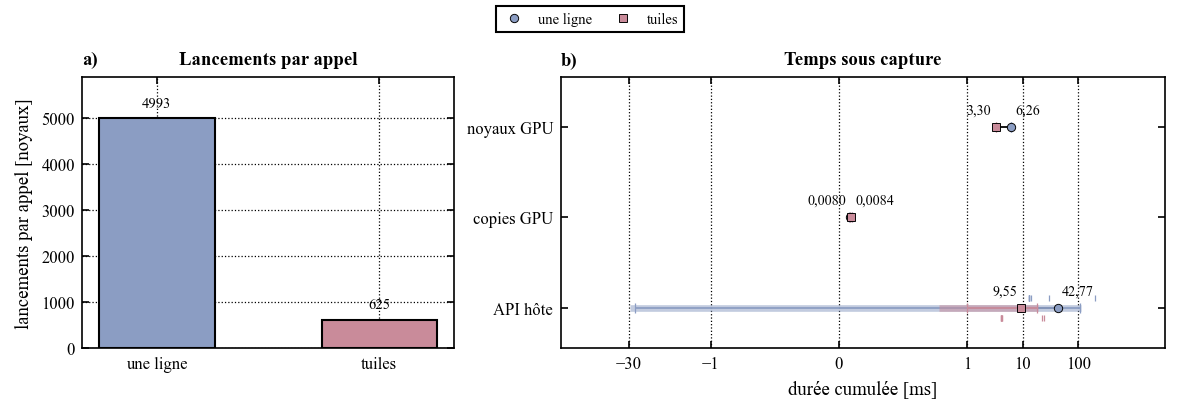

In [10]:
# Répétition indépendante du profilage d’une paire après chauffe.
ns_raw = nv_csv(RES / "repeated/gpu-trace/838775/captures.csv")
assert ns_raw.groupby("variant").block.nunique().eq(7).all()
assert ns_raw.distance.eq(99).all() and ns_raw.groupby("variant").launches.nunique().eq(1).all()
ns_vars = ns_raw.groupby("variant").launches.first().sort_values(ascending=False).index
ns_fig, ns_ax = plt.subplots(1, 2, figsize=(7.75, 2.65), width_ratios=[0.8, 1.3])
for ns_j, ns_var in enumerate(ns_vars):
    ns_count = int(ns_raw[ns_raw.variant.eq(ns_var)].launches.iloc[0])
    nv_stats.add(9, "launches", ns_var, "5k", [ns_count], "exact_capture_count", independent=False)
    ns_ax[0].bar(ns_j, ns_count, color=COLORS[ns_j], edgecolor=INK, width=0.52)
    value_label(ns_ax[0], ns_j, ns_count, ns_count, 0)
ns_ax[0].set(
    xticks=[0, 1],
    xticklabels=["une ligne", "tuiles"],
    ylabel="lancements par appel [noyaux]",
    ylim=(0, 1.18 * ns_raw.launches.max()),
)
for ns_i, ns_domain in enumerate(["kernel_ms", "copy_ms", "api_ms"]):
    ns_entries = []
    for ns_j, ns_var in enumerate(ns_vars):
        ns_data = ns_raw[ns_raw.variant.eq(ns_var)][ns_domain]
        ns_s = nv_stats.add(9, ns_domain, ns_var, "5k", ns_data, "independent_nsight_process")
        ns_entries.append((ns_s, COLORS[ns_j], "os"[ns_j], ["une ligne", "tuiles"][ns_j]))
    comparison(ns_ax[1], ns_i, ns_entries, digits=4 if ns_domain == "copy_ms" else 2)
    if ns_domain == "api_ms":
        for ns_j, ns_var in enumerate(ns_vars):
            ns_vals = ns_raw[ns_raw.variant.eq(ns_var)].api_ms
            ns_ax[1].plot(
                ns_vals,
                np.full(len(ns_vals), ns_i + (ns_j - 0.5) * 0.22),
                marker="|",
                ls="none",
                ms=3,
                color=COLORS[ns_j],
            )
ns_ax[1].set_xscale("symlog", linthresh=0.03, linscale=0.7)
ns_ax[1].set_xticks([-30, -1, 0, 1, 10, 100], ["−30", "−1", "0", "1", "10", "100"])
category_rows(ns_ax[1], ["noyaux GPU", "copies GPU", "API hôte"], "durée cumulée [ms]")
label_panels(ns_ax)
column_titles(ns_ax, ("Lancements par appel", "Temps sous capture"))
legend_above(ns_fig, ns_ax, ncol=2)
nv_save(ns_fig, "gpu/trace_cuda")

*Figure 9.* La paire de 5 000 et 4 992 bases est d’abord alignée hors capture, puis profilée dans sept processus neufs par variante. À gauche, le décompte de lancements est identique pour les sept captures. À droite, les durées de la capture sont résumées entre processus, séparément pour chaque domaine.

<sub>Code : [bench/repeated/trace/gpu_trace.py](../bench/repeated/trace/gpu_trace.py), [results/repeated/gpu-trace/838775/captures.csv](../results/repeated/gpu-trace/838775/captures.csv), [results/repeated/gpu-trace/838775/operations.csv](../results/repeated/gpu-trace/838775/operations.csv).</sub>

Les sept captures comptent 4 993 lancements pour le noyau par ligne et 625 pour les tuiles. L’API hôte de la version initiale présente un appel de lot à 203,14 ms. Sa moyenne vaut 42,77 ms avec un écart-type de 70,99 ms. La borne basse de l’IC de Student atteint −22,89 ms. La figure conserve l’intervalle entier et indique les sept observations de ce domaine. Le chronométrage de l’API hôte comprend les opérations de gestion mémoire et les appels du profileur enregistrés.

La variation de l’ordre de lecture offre une autre observation de la hiérarchie mémoire.

<p><strong><u>Synthèse.</u></strong> Les noyaux cumulent en moyenne 6,265 ms avec un lancement par ligne et 3,296 ms avec les tuiles sur cet alignement.<br>Les durées des copies restent proches de 0,008 ms tandis que les appels hôtes fluctuent.</p>

<a id="localite-gpu"></a>

## Localité des lectures en mémoire globale

<hr>

La figure 10 compare le regroupement des adresses des warps entre les noyaux par ligne et la politique de tuiles.

Pour les adresses en octets $a_t$ des fils actifs d’un warp, le modèle compte $N_s=|\{\lfloor a_t/32\rfloor\}|$ secteurs de 32 octets par instruction logique. Le modèle suppose le découpage des adresses fourni par les noyaux. Il ne connaît ni les résidences en cache ni les transactions HBM.

La sonde rejoue les accès des warps à l’index, à la diagonale, au prédécesseur vertical, au prédécesseur de dernière occurrence et aux écritures globales. La somme des octets des secteurs divisée par le nombre de cases mesure les demandes logiques. La fraction utile compte les mots distincts de quatre octets dans chaque instruction de warp. L’initialisation, les transferts entre hôte et GPU et les lectures en mémoire partagée sont exclus. Un secteur déjà en cache peut être demandé à nouveau par une autre instruction.

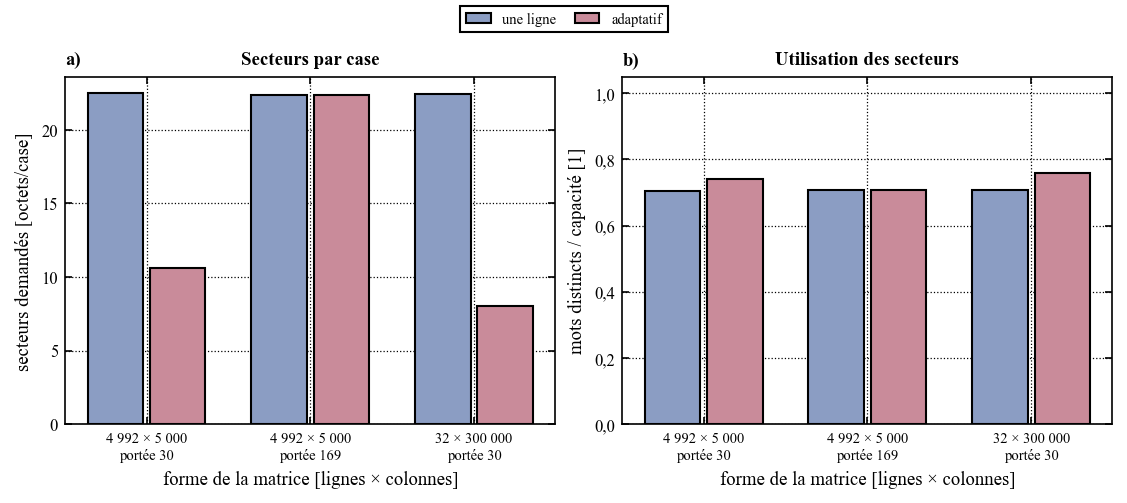

In [11]:
# Secteurs d'adresse demandés par instruction de warp, modèle de 32 octets.
loc_raw = nv_csv(RES / "locality/838447/sectors.csv")
assert set(loc_raw.schedule) == {"adaptive", "single_row"}
assert set(loc_raw.access) == {"mit", "diagonal", "upper", "gather", "store"}
assert loc_raw.groupby("case").distance.nunique().eq(1).all()
loc_tot = loc_raw.groupby(["case", "schedule"])[["sectors32", "distinct_words"]].sum()
loc_dims = loc_raw.groupby("case")[["rows", "columns", "reach"]].first()
loc_cells = loc_dims.rows * loc_dims["columns"]
loc_bytes = (32 * loc_tot.sectors32 / loc_cells).unstack()
loc_fill = (loc_tot.distinct_words / (8 * loc_tot.sectors32)).unstack()
assert loc_fill.ge(0).all().all() and loc_fill.le(1).all().all()
loc_cases = list(loc_dims.sort_values(["columns", "reach"]).index)
loc_labels = [
    f"{int(loc_dims.loc[c, 'rows']):,} × {int(loc_dims.loc[c, 'columns']):,}".replace(",", " ")
    + f"\nportée {int(loc_dims.loc[c, 'reach'])}"
    for c in loc_cases
]
loc_fig, loc_ax = plt.subplots(1, 2, figsize=(7.4, 3.25))
loc_x = np.arange(len(loc_cases))
for loc_ix, (loc_variant, loc_name) in enumerate(
    [("single_row", "une ligne"), ("adaptive", "adaptatif")]
):
    loc_xi = loc_x + (loc_ix - 0.5) * 0.38
    for loc_axis, loc_data in [(loc_ax[0], loc_bytes), (loc_ax[1], loc_fill)]:
        loc_axis.bar(
            loc_xi,
            loc_data.loc[loc_cases, loc_variant],
            width=0.34,
            color=COLORS[loc_ix],
            edgecolor=INK,
            label=loc_name,
        )
loc_ax[0].set_ylabel("secteurs demandés [octets/case]")
loc_ax[1].set(ylabel="mots distincts / capacité [1]", ylim=(0, 1.05))
for loc_axis in loc_ax:
    loc_axis.set_xticks(loc_x, loc_labels, fontsize=7)
    loc_axis.set_xlabel("forme de la matrice [lignes × colonnes]")
for loc_key in loc_cases:
    for loc_policy in ["single_row", "adaptive"]:
        loc_bytes = (
            32
            * loc_tot.loc[(loc_key, loc_policy), "sectors32"]
            / (loc_dims.loc[loc_key, "rows"] * loc_dims.loc[loc_key, "columns"])
        )
        nv_stats.add(
            10,
            "sector_bytes_per_cell",
            loc_policy,
            loc_key,
            [loc_bytes],
            "deterministic_address_model",
            independent=False,
        )
label_panels(loc_ax)
column_titles(loc_ax, ("Secteurs par case", "Utilisation des secteurs"))
legend_above(loc_fig, loc_ax, ncol=2)
nv_save(loc_fig, "gpu/localite_gpu")

*Figure 10.* Le panneau a) rapporte la somme des octets des secteurs de 32 octets demandés au nombre de cases. Le panneau b) mesure la part de ces octets qui correspond à des mots distincts dans l’instruction de warp. Les sommes couvrent tout le traitement des lignes.

<sub>Code : [bench/gpu/locality/gpu_sectors.cu](../bench/gpu/locality/gpu_sectors.cu), [bench/gpu/locality/gpu_sectors.sbatch](../bench/gpu/locality/gpu_sectors.sbatch), [results/locality/838447/sectors.csv](../results/locality/838447/sectors.csv), [results/locality/838447/requested-metrics.txt](../results/locality/838447/requested-metrics.txt).</sub>

Pour la forme de 4992 × 5000 cases, le calcul adaptatif demande 10,62 octets de secteurs par case, contre 22,48 pour une ligne à la fois. Pour la forme de 32 × 300000 cases, le calcul adaptatif demande 8,03 octets de secteurs par case, contre 22,42 pour une ligne à la fois. Sur le contrôle de grande portée, la récurrence utilise le noyau par ligne. Les deux décomptes de secteurs coïncident. Dans la forme large, les mots distincts remplissent 75,8 % des octets demandés par la politique adaptative. Les compteurs L1 et L2 demandés à Nsight Compute ont renvoyé ERR_NVGPUCTRPERM.

Les allocations entre deux alignements représentent un coût distinct de celui des accès du noyau.

<p><strong><u>Synthèse.</u></strong> Sur la forme large, les tuiles divisent par 2,79 les octets de secteurs demandés par case.<br>Ce rapport décrit les adresses du noyau. Le trafic HBM dépend aussi de l’état des caches.</p>

<a id="front-gpu"></a>

## Calcul par fronts de coût sur accélérateur

<hr>

La figure 11 compare les durées de trois programmes avec reconstruction du chemin et vérifie le domaine de distance du front GPU.

Pour un chemin d’édition unitaire de coût $s$, toute position $(i,j)$ vérifie $|i-j|\leq s$. Le front $s$ garde la position la plus avancée sur chaque diagonale accessible, puis prolonge les correspondances gratuites. L’implémentation IEEE 2022 testée représente uniquement $d<64$. Elle traite plusieurs paires en lot. [Aguado-Puig et coll., 2022](https://doi.org/10.1109/ACCESS.2022.3182714)

Les trois lots admissibles contiennent cinq préfixes à 2 %, quatre préfixes à 5 % et cinq paires complètes de 5 000 bases à faible distance. Un appel indépendant par configuration donne le score et un chemin. Edlib établit le coût de référence avant la sélection, puis le pilote rejoue le chemin. Les cinq répétitions chronométrent chacune un processus neuf. Le temps du lot annoncé par eWFA-GPU débute après lecture et initialisation de CUDA.

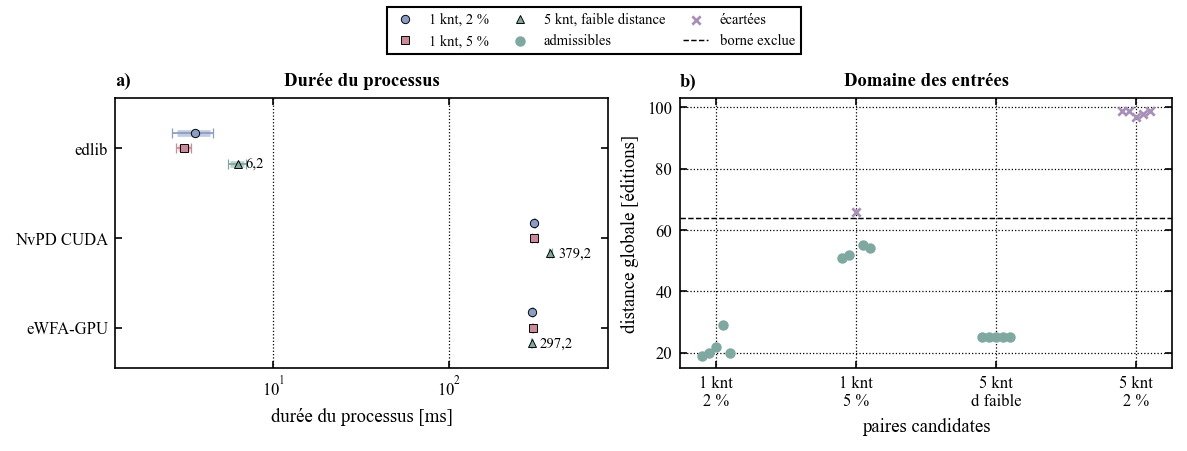

In [12]:
# Temps des processus avec chemin d'alignement et borne de la version IEEE 2022.
ew_dir = RES / "ewfa/838492"
ew_cases = ["1k_prefix_2pct", "1k_prefix_5pct", "5k_full_low"]
ew_raw = nv_csv(ew_dir / "trials.csv")
ew_pairs = nv_csv(ew_dir / "pairs.csv")
ew_ok = ew_pairs[ew_pairs.status.eq("verified")]
assert ew_ok.edlib.eq(pd.to_numeric(ew_ok.gpu_score)).all()
assert ew_ok.edlib.eq(pd.to_numeric(ew_ok.raw_cigar_cost)).all()
assert ew_ok.edlib.lt(64).all() and len(ew_ok) == 14
assert ew_pairs[ew_pairs.status.eq("outside_d_lt_64")].edlib.ge(64).all()
assert ew_raw.groupby(["case", "algorithm"]).trial.nunique().eq(5).all()
ew_fig, ew_ax = plt.subplots(1, 2, figsize=(7.8, 2.9))
ew_legend = ["1 knt, 2 %", "1 knt, 5 %", "5 knt, faible distance"]
for ew_i, (ew_alg, ew_name) in enumerate(
    [("edlib", "edlib"), ("nvpd-cuda", "NvPD CUDA"), ("ewfa-gpu-2022", "eWFA-GPU")]
):
    for ew_j, ew_case in enumerate(ew_cases):
        ew_values = ew_raw[ew_raw.case.eq(ew_case) & ew_raw.algorithm.eq(ew_alg)].process_seconds * 1000
        ew_res = nv_stats.add(11, "process_ms", ew_alg, ew_case, ew_values, "fresh_process")
        estimate(
            ew_ax[0],
            ew_i + (ew_j - 1) * 0.17,
            ew_res,
            COLORS[ew_j],
            marker="os^"[ew_j],
            horizontal=True,
            label=ew_legend[ew_j],
        )
    value_label(ew_ax[0], ew_res["mean"], ew_i + 0.17, ew_res["mean"], 1, horizontal=True)
ew_ax[0].set_xscale("log")
category_rows(ew_ax[0], ["edlib", "NvPD CUDA", "eWFA-GPU"], "durée du processus [ms]")
ew_all_cases = [*ew_cases, "5k_full_2pct"]
for ew_i, ew_case in enumerate(ew_all_cases):
    ew_rows = ew_pairs[ew_pairs.case.eq(ew_case)]
    for ew_j, ew_row in enumerate(ew_rows.itertuples()):
        ew_valid = ew_row.status == "verified"
        ew_ax[1].scatter(
            ew_i + 0.05 * (ew_j - (len(ew_rows) - 1) / 2),
            ew_row.edlib,
            marker="o" if ew_valid else "x",
            color=COLORS[2] if ew_valid else COLORS[5],
            label="admissibles" if ew_valid else "écartées",
            zorder=3,
        )
ew_ax[1].axhline(64, **GUIDE, label="borne exclue")
ew_ax[1].set(ylabel="distance globale [éditions]", xlabel="paires candidates")
ew_ax[1].set_xticks(np.arange(4), ["1 knt\n2 %", "1 knt\n5 %", "5 knt\nd faible", "5 knt\n2 %"])
label_panels(ew_ax)
column_titles(ew_ax, ("Durée du processus", "Domaine des entrées"))
legend_above(ew_fig, ew_ax, ncol=3)
nv_save(ew_fig, "gpu/front_gpu")

*Figure 11.* À gauche, le temps mural comprend le démarrage et le calcul des chemins. Cinq processus indépendants sont mesurés après un processus de chauffe écarté pour chaque programme et lot. À droite figurent toutes les paires candidates et la borne stricte imposée par cette livraison d’eWFA-GPU.

<sub>Code : [bench/gpu/ewfa/ewfa_measure.py](../bench/gpu/ewfa/ewfa_measure.py), [bench/gpu/ewfa/ewfa_batch.cpp](../bench/gpu/ewfa/ewfa_batch.cpp), [bench/gpu/ewfa/ewfa_validation.patch](../bench/gpu/ewfa/ewfa_validation.patch), [results/ewfa/838492/trials.csv](../results/ewfa/838492/trials.csv), [results/ewfa/838492/pairs.csv](../results/ewfa/838492/pairs.csv).</sub>

Sur le lot des préfixes à 2 %, le processus eWFA-GPU dure en moyenne 299,9 (écart-type 2,3, IC 95 % de 297,1 à 302,7) ms. Le chronomètre interne d’amont commence après la lecture et l’initialisation du contexte. Les chemins binaires ont été rejoués pour chaque paire admissible. Le formateur texte de la livraison amont modifie le CIGAR lors de son affichage.

Les lots permettent aussi de distinguer le lancement du processus et le coût des allocations successives.

<p><strong><u>Synthèse.</u></strong> La livraison IEEE de 2022 accepte 14 des 20 paires proposées avec sa borne stricte de 64 éditions.<br>Les lots de quatre ou cinq paires évaluent surtout le coût de démarrage.</p>

<a id="allocations-cuda"></a>

## Réutilisation des tampons entre alignements

<hr>

La figure 12 montre dans quelles collections la réutilisation des tableaux GPU réduit le coût des allocations.

Pour le lot $b$ et la répétition $r$, le gain apparié vaut $S_{b,r}=T_{b,r}^{\rm normal}/T_{b,r}^{\rm reuse}$. Le point représente la moyenne des trois rapports. Chaque exécution comprend la première allocation et la libération finale.

Le premier mode réserve et libère les deux tableaux CUDA pour chaque paire. Le second les conserve lorsque leurs tailles restent identiques. Trois lots synthétiques contiennent des séquences de même longueur. Le quatrième contient 64 génomes de φX174 de longueurs variables. L’oracle edlib et l’appel de chauffe précèdent chaque lot. Chaque mode tourne dans un processus neuf et l’ordre alterne entre les répétitions.

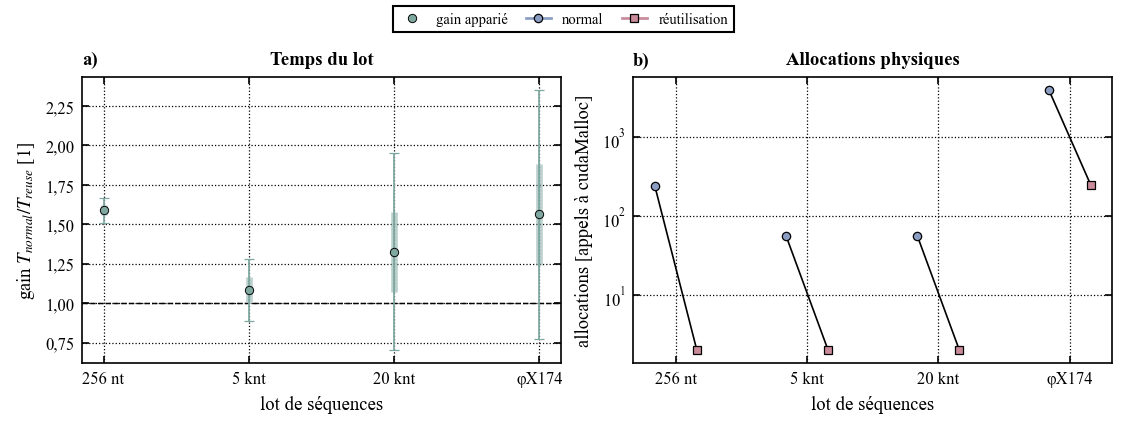

In [13]:
# Comparaison appariée sur des lots contrôlés, hors capture Nsight.
pool_alloc = nv_csv(RES / "allocator/trials.csv")
assert set(pool_alloc["mode"]) == {"normal", "reuse"}
assert set(pool_alloc["case"]) == {"fixed-256", "fixed-5000", "fixed-20000", "phix174"}
assert pool_alloc.groupby(["case", "trial"]).size().eq(2).all()
assert pool_alloc.groupby(["case", "mode"]).trial.nunique().eq(3).all()
for pool_column in ["distance_fnv64", "input_sha256", "pairs", "peak_live_bytes"]:
    assert pool_alloc.groupby("case")[pool_column].nunique().eq(1).all()
assert pool_alloc.malloc_calls.eq(pool_alloc.free_calls).all()
assert pool_alloc.groupby("case").peak_reserved_bytes.nunique().eq(1).all()
assert pool_alloc.malloc_calls.add(pool_alloc.reuse_hits).eq(2 * pool_alloc.pairs).all()
pool_ab = pool_alloc.pivot(index=["case", "trial"], columns="mode", values="seconds")
pool_cases = ["fixed-256", "fixed-5000", "fixed-20000", "phix174"]
pool_x = np.arange(len(pool_cases))
pool_labels = ["256 nt", "5 knt", "20 knt", "φX174"]
pool_fig, pool_ax = plt.subplots(1, 2, figsize=(7.4, 2.75))
pool_ratio = (pool_ab.normal / pool_ab.reuse).droplevel("trial")
nv_plot(
    pool_ax[0],
    pool_ratio,
    pool_cases,
    pool_x,
    12,
    "paired_speedup",
    "normal/reuse",
    "paired_process_block",
    COLORS[2],
    label="gain apparié",
)
pool_ax[0].axhline(1, **GUIDE)
pool_ax[0].set(ylabel=r"gain $T_{normal}/T_{reuse}$ [1]", xlabel="lot de séquences")
for pool_idx, pool_case in enumerate(pool_cases):
    pool_c = pool_alloc[pool_alloc.case.eq(pool_case)].groupby("mode").malloc_calls
    assert pool_c.nunique().eq(1).all()
    pool_values = pool_c.first().reindex(["normal", "reuse"]).to_numpy()
    pool_ax[1].plot([pool_idx - 0.16, pool_idx + 0.16], pool_values, color=INK, linewidth=0.8)
    for pool_j, pool_v in enumerate(pool_values):
        pool_ax[1].plot(
            pool_idx + (pool_j - 0.5) * 0.32,
            pool_v,
            marker="os"[pool_j],
            color=COLORS[pool_j],
            markeredgecolor=INK,
            label=["normal", "réutilisation"][pool_j],
        )
pool_ax[1].set(yscale="log", ylabel="allocations [appels à cudaMalloc]", xlabel="lot de séquences")
for pool_axis in pool_ax:
    pool_axis.set_xticks(pool_x, pool_labels)
label_panels(pool_ax)
column_titles(pool_ax, ("Temps du lot", "Allocations physiques"))
legend_above(pool_fig, pool_ax, ncol=3)
nv_save(pool_fig, "gpu/allocations_cuda")

*Figure 12.* La sonde chauffe une paire avant de mesurer chaque lot dans un processus indépendant. Le gain est calculé dans chacun des trois blocs normal/réutilisation. Les appels d’allocation du panneau b) sont des décomptes exacts de la sonde.

<sub>Code : [bench/gpu/allocation/allocator_probe.cu](../bench/gpu/allocation/allocator_probe.cu), [bench/gpu/allocation/allocator_measure.py](../bench/gpu/allocation/allocator_measure.py), [results/allocator/trials.csv](../results/allocator/trials.csv), [results/allocator/production.csv](../results/allocator/production.csv).</sub>

Pour les 2 016 paires de phages, le gain moyen de la sonde d’allocation vaut 1,56 (écart-type 0,32, IC 95 % de 0,77 à 2,35). Le double tampon persistant réduit les allocations physiques de 4 032 à 250. Le pic explicite reste de 150 892 octets dans les deux modes pour ce lot.

Un autre portage permet d’évaluer le coût de la même récurrence dans un espace d’exécution générique.

<p><strong><u>Synthèse.</u></strong> Deux tampons de même taille peuvent servir aux paires successives d’un lot.<br>Le nombre d’allocations dépend des changements de longueur dans l’ordre des 2 016 paires.</p>

<a id="kokkos"></a>

## Portabilité de la récurrence avec Kokkos

<hr>

La figure 13 évalue deux implémentations de NvPD utilisant la même cible matérielle.

À matériel et séquences fixés, le rapport $T_{\rm Kokkos}/T_{\rm native}$ inclut les choix de noyau et le mode de lancement. Chaque processus réalise un appel de chauffe avant l’appel chronométré. [Edwards, Trott et Sunderland, 2014](https://doi.org/10.1016/j.jpdc.2014.07.003)

Un espace d’exécution Kokkos choisit où se déroule une boucle. Le même programme source peut soumettre une ligne de NvPD à OpenMP sur CPU ou à CUDA sur GPU. Dans ce portage, une `RangePolicy` distribue les colonnes de chaque ligne et une barrière `fence` précède la récupération du score. Sur GPU, le noyau Kokkos suit la récurrence ligne par ligne, tandis que la version CUDA native peut regrouper huit lignes en tuiles. Un processus neuf effectue un appel de chauffe puis un appel chronométré, allocations et transferts compris. Les deux implémentations alternent leur ordre entre les trois répétitions sur les mêmes entrées. Le GPU utilise CUDA 12.6.3 et l’espace d’exécution `Kokkos::Cuda`. [Boucles parallèles Kokkos](https://kokkos.org/kokkos-core-wiki/API/core/parallel-dispatch/parallel_for.html) · [Synchronisation Kokkos](https://kokkos.org/kokkos-core-wiki/API/core/parallel-dispatch/fence.html)

Trois allocations du même nœud EPYC et trois du même GH200 fournissent la répétition. Pour chaque variante et chaque taille, la moyenne de trois processus dans une allocation constitue une observation. L’échantillon renseigne les variations entre réservations de ces nœuds.

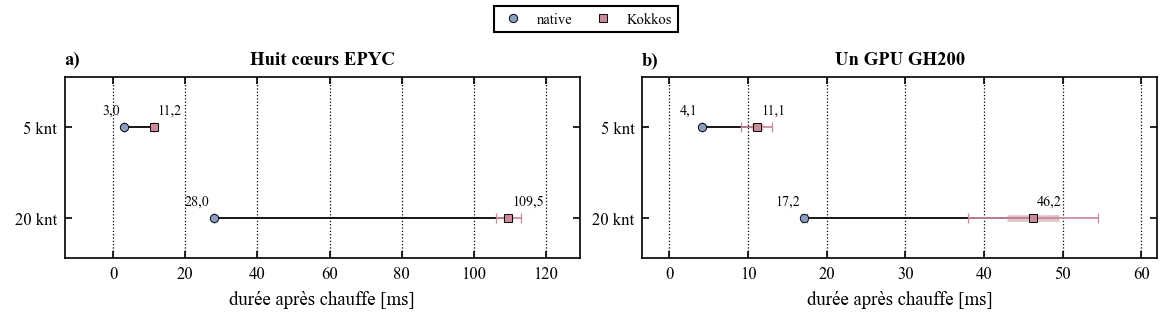

In [14]:
# Coût du portage Kokkos par rapport à l'implémentation native de chaque cible.
ko_raw = nv_csv(RES / "kokkos/timings.csv")
assert ko_raw.distance.eq(ko_raw.reference_distance).all()
ko_repeat = nv_csv(RES / "kokkos/replications/trials.csv")
ko_raw = pd.concat([ko_raw, ko_repeat], ignore_index=True)
assert ko_raw.distance.eq(ko_raw.reference_distance).all()
assert not ko_raw.duplicated(["job", "target", "threads", "m", "algorithm", "trial"]).any()
ko_fig, ko_ax = plt.subplots(1, 2, figsize=(7.7, 2.05))
for ko_i, (ko_target, ko_native) in enumerate([("cpu", "nvpd-omp"), ("gpu", "nvpd-cuda")]):
    ko_sub = ko_raw[ko_raw.target.eq(ko_target)]
    ko_sub = ko_sub[ko_sub.threads.eq(ko_sub.threads.max())]
    assert ko_sub.groupby(["m", "algorithm"]).trial.nunique().eq(3).all()
    assert ko_sub.groupby("m").input_sha256.nunique().eq(1).all()
    for ko_y, ko_size in enumerate([5000, 20000]):
        ko_entries = []
        for ko_j, ko_alg in enumerate([ko_native, "nvpd-kokkos"]):
            ko_select = ko_sub[ko_sub.algorithm.eq(ko_alg) & ko_sub.m.eq(ko_size)]
            assert ko_select.groupby("job").size().eq(3).all() and ko_select.job.nunique() == 3
            ko_values = ko_select.groupby("job").seconds.mean() * 1000
            ko_unit = "allocation_mean_of_three_processes"
            ko_res = nv_stats.add(13, "ms_" + ko_target, ko_alg, ko_size, ko_values, ko_unit)
            ko_entries.append((ko_res, COLORS[ko_j], "os"[ko_j], ["native", "Kokkos"][ko_j]))
        comparison(ko_ax[ko_i], ko_y, ko_entries, digits=1)
    category_rows(ko_ax[ko_i], ["5 knt", "20 knt"], "durée après chauffe [ms]")
label_panels(ko_ax)
column_titles(ko_ax, ("Huit cœurs EPYC", "Un GPU GH200"))
legend_above(ko_fig, ko_ax, ncol=2)
nv_save(ko_fig, "distributed/portage_kokkos")

*Figure 13.* Une ligne réunit la version native et Kokkos sur une même paire. Sur chaque plateforme, les points résument trois allocations du même nœud. Chaque allocation fournit la moyenne de trois processus préchauffés par méthode et par taille. Les barres représentent la dispersion et l’IC entre ces trois moyennes.

<sub>Code : [bench/kokkos/kokkos_measure.py](../bench/kokkos/kokkos_measure.py), [results/kokkos/timings.csv](../results/kokkos/timings.csv), [results/kokkos/checks.csv](../results/kokkos/checks.csv), [results/kokkos/replications/trials.csv](../results/kokkos/replications/trials.csv).</sub>

Sur huit cœurs EPYC à 20 knt, le backend OpenMP natif prend 27,95 (écart-type 0,04, IC 95 % de 27,86 à 28,05) ms et l’espace Kokkos OpenMP 109,53 ms. Sur GH200, les temps moyens respectifs valent 17,18 et 46,23 ms.

La distribution sur plusieurs nœuds ajoute la communication entre rangs.

<p><strong><u>Synthèse.</u></strong> Les deux espaces d’exécution retrouvent les mêmes distances sur les paires de 5 et 20 knt.<br>Pour ces tailles, les implémentations natives prennent moins de temps sur les deux cibles.</p>

<a id="mpi-fort"></a>

## Passage à l’échelle fort entre nœuds

<hr>

La figure 14 compare les communications d’une paire distribuée à celles d’une collection de paires indépendantes.

Pour aligner une seule paire, chaque rang MPI conserve une bande de colonnes. À chaque ligne, il partage deux scores entiers avec tous les rangs pour résoudre les dépendances qui traversent une frontière. L’expérience affecte 24 rangs de huit fils OpenMP à chaque nœud. Pour une collection, le programme distribue des paires indépendantes entre les rangs puis entre les fils OpenMP. Une seule réduction finale réunit les distances. Un nœud compte 192 cœurs actifs et deux nœuds en comptent 384 avec la même disposition des équipes. [Implémentation distribuée](../src/mpi/mpi.cpp) · [Norme MPI, opérations collectives](https://www.mpi-forum.org/docs/mpi-4.1/mpi41-report/mpi41-report.htm)

Les mesures à un et deux nœuds utilisent les mêmes séquences dans une réservation exclusive. Chaque essai commence après une barrière, puis le pilote conserve la durée du rang le plus lent. Le rapport $S=T_1/T_2$ donne le gain du second nœud. L’efficacité de ce doublement est $S/2$. Les sept blocs indépendants changent l’ordre des configurations. Chaque lancement effectue deux calculs de chauffe et une mesure.

MPI définit les communications collectives entre processus. Allgather distribue à chaque rang les données fournies par tous les autres rangs. [MPI Forum, spécification](https://www.mpi-forum.org/docs/mpi-4.1/mpi41-report/mpi41-report.htm)

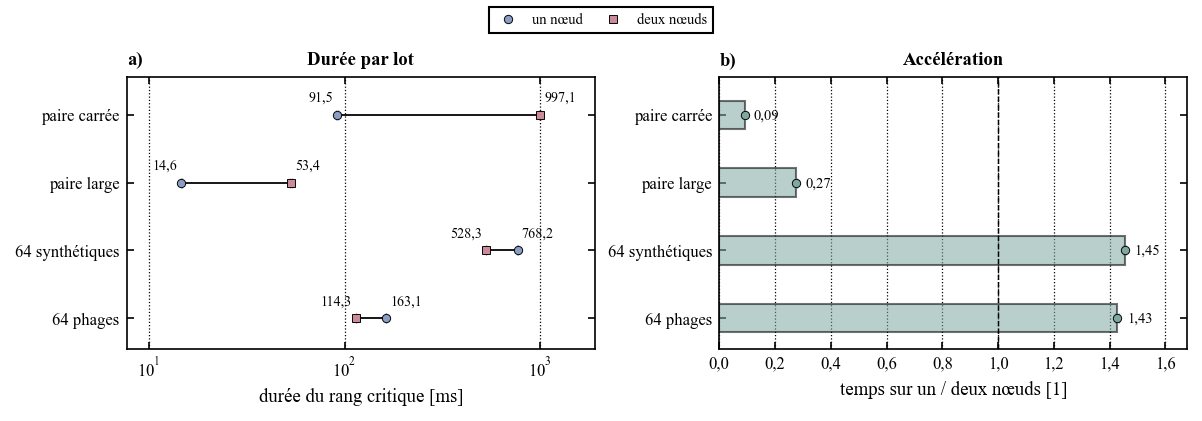

In [15]:
# Passage à l’échelle fort entre lancements indépendants.
mp_cases = {
    "square": "paire\n20 k × 20 k",
    "wide": "paire\n1 k × 1 M",
    "synthetic64": "64 séquences\nsynthétiques",
    "phix64": "64 phages\nφX174",
}
mp_x = np.arange(len(mp_cases))
# Contrôle du second essai sur un seul nœud, chronométré du lancement à la sortie.
mp_cli = nv_csv(RES / "profile/matrix-omp/838652/trials.csv")
assert mp_cli.threads.eq(8).all() and mp_cli.pairs.eq(120).all()
assert mp_cli.input_sha256.nunique() == mp_cli.matrix_sha256.nunique() == 1
mp_cli_wall = mp_cli.pivot(index="trial", columns="layout", values="wall_seconds")
assert mp_cli_wall.shape == (5, 2) and mp_cli_wall.notna().all().all()
mp_cli_gain = nv_stats.add(
    14,
    "single_node_gain",
    "intra/inter",
    "120_pairs",
    mp_cli_wall["intra"] / mp_cli_wall["inter"],
    "paired_process_block",
)
mp_repeat = nv_csv(RES / "mpi/scaling/trials.csv")
mp_repeat = mp_repeat[mp_repeat.study.eq("strong")]
assert mp_repeat.groupby(["case", "nodes"]).block.nunique().eq(7).all()
assert mp_repeat.physical_cores.eq(192 * mp_repeat.nodes).all()
mp_pair = mp_repeat.pivot(index=["case", "block"], columns="nodes", values="seconds")
mp_paired = (mp_pair[1] / mp_pair[2]).droplevel("block")
mp_fig, mp_ax = plt.subplots(1, 2, figsize=(7.9, 2.7))
mp_names = ["paire carrée", "paire large", "64 synthétiques", "64 phages"]
for mp_row, mp_case in enumerate(mp_cases):
    mp_entries = []
    for mp_i, mp_n in enumerate([1, 2]):
        mp_vals = mp_repeat[mp_repeat.case.eq(mp_case) & mp_repeat.nodes.eq(mp_n)].seconds * 1000
        mp_rec = nv_stats.add(14, "milliseconds", str(mp_n), mp_case, mp_vals, "independent_mpirun")
        mp_entries.append((mp_rec, COLORS[mp_i], "os"[mp_i], ["un nœud", "deux nœuds"][mp_i]))
    comparison(mp_ax[0], mp_row, mp_entries, digits=1)
    mp_rat = nv_stats.add(14, "ratio", "1/2", mp_case, mp_paired.loc[mp_case], "paired_mpirun_block")
    mp_ax[1].barh(mp_row, mp_rat["mean"], height=0.42, color=COLORS[2], alpha=0.55, edgecolor=INK)
    estimate(mp_ax[1], mp_row, mp_rat, COLORS[2], horizontal=True)
    value_label(mp_ax[1], mp_rat["high95"], mp_row, mp_rat["mean"], 2, horizontal=True)
mp_ax[0].set_xscale("log")
category_rows(mp_ax[0], mp_names, "durée du rang critique [ms]")
category_rows(mp_ax[1], mp_names, "temps sur un / deux nœuds [1]")
mp_ax[1].axvline(1, **GUIDE)
label_panels(mp_ax)
column_titles(mp_ax, ("Durée par lot", "Accélération"))
legend_above(mp_fig, mp_ax, ncol=3)
nv_save(mp_fig, "distributed/echelle_mpi")

*Figure 14.* Chaque marqueur de durée résume sept lancements MPI indépendants, chacun après deux calculs de chauffe. L’ordre des configurations change à chaque bloc. Le rapport sur un et deux nœuds est calculé à l’intérieur du bloc avant la moyenne et l’IC.

<sub>Code : [src/mpi/mpi.cpp](../src/mpi/mpi.cpp), [bench/mpi/scaling.py](../bench/mpi/scaling.py), [results/mpi/scaling/trials.csv](../results/mpi/scaling/trials.csv), [bench/cpu/openmp/matrix_omp.py](../bench/cpu/openmp/matrix_omp.py), [results/profile/matrix-omp/838652/trials.csv](../results/profile/matrix-omp/838652/trials.csv).</sub>

La division des colonnes exige un échange de frontières à chaque ligne. La distribution des paires demande une réduction du résultat final. Sur la collection de phages, le gain apparié vaut 1,427 (écart-type 0,007, IC 95 % de 1,421 à 1,433). Un essai séparé à huit cœurs sur un seul nœud regroupe 120 paires dans la même commande. Les cinq blocs alternent les deux ordres. Le gain moyen en répartissant les paires vaut 5,250 (écart-type 0,041, IC 95 % de 5,200 à 5,301). Les dix matrices coïncident avec edlib.

Le passage à l’échelle faible conserve la charge par nœud pour examiner séparément son effet.

<p><strong><u>Synthèse.</u></strong> La granularité de la communication distingue les alignements isolés et les collections de 64 entrées.<br>Les deux distributions terminent avec les mêmes scores.</p>

<a id="collective-mpi"></a>

## Temps passé dans les échanges collectifs

<hr>

La figure 15 examine le coût de l’échange à chaque ligne sur le rang qui termine le dernier.

La couche de profilage PMPI intercepte Allgather et accumule son temps sur chaque rang de l’alignement. Pour le rang critique $r^*$, la fraction $f=T_{gather,r^*}/T_{r^*}$ inclut l’attente des autres rangs à l’intérieur de la collective. Le reste $T_{r^*}-T_{gather,r^*}$ couvre les autres opérations. Chaque bloc lance à nouveau les huit configurations (deux formes, deux nombres de nœuds, avec ou sans sonde), dans un ordre aléatoire. Les deux calculs de chauffe précèdent la mesure dans chaque lancement. [MPI Forum, interface de profilage](https://www.mpi-forum.org/docs/mpi-4.1/mpi41-report/mpi41-report.htm)

Une seconde allocation compare l’échange collectif au transfert du bord droit vers le rang voisin après chaque paquet de $H$ lignes de la matrice. Des paquets plus hauts réduisent la fréquence des messages, mais un rang en aval attend la préparation du paquet. L’essai compare $H=8$ et $H=32$ au témoin Allgather, sur les mêmes deux nœuds et entrées pour les trois méthodes. Un rapport de 1 indiquerait des durées égales.

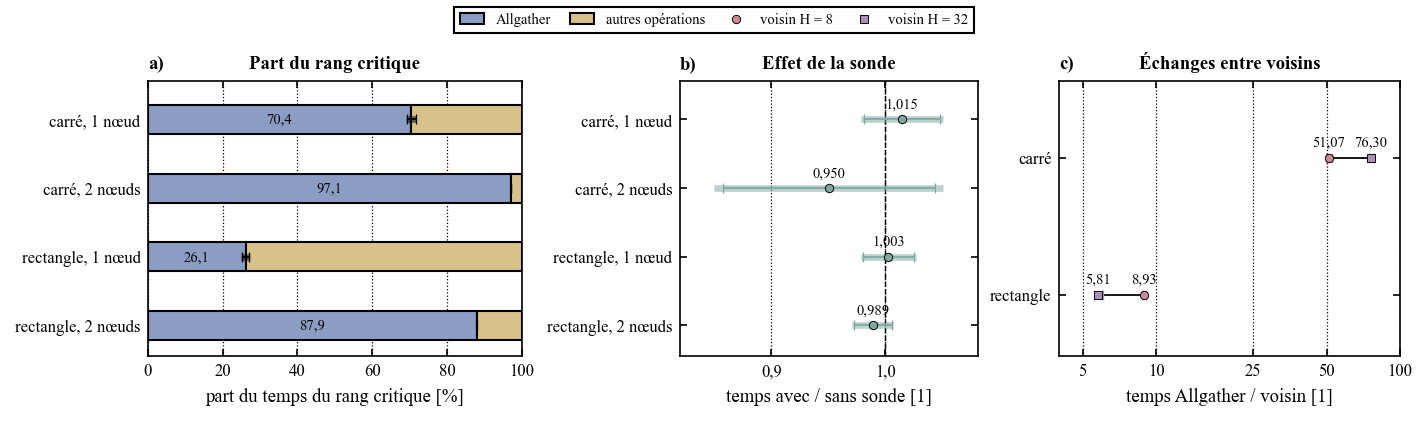

In [16]:
# Temps du rang critique, dans la même invocation instrumentée.
cm_raw = nv_csv(RES / "mpi/collectives/trials.csv")
assert cm_raw.groupby(["case", "nodes", "instrumented"]).block.nunique().eq(7).all()
assert cm_raw.physical_cores.eq(192 * cm_raw.nodes).all()
cm_active = cm_raw[cm_raw.instrumented.eq(1)].copy()
cm_active["fraction"] = 100 * pd.to_numeric(cm_active.collective_seconds) / cm_active.seconds
cm_active["remaining"] = cm_active.seconds - pd.to_numeric(cm_active.collective_seconds)
assert cm_active.fraction.between(0, 100).all()
cm_measures = cm_raw.pivot(index=["case", "nodes", "block"], columns="instrumented", values="seconds")
cm_fig, cm_ax = plt.subplots(1, 3, figsize=(9.4, 2.7), width_ratios=[1.13, 0.9, 1.03])
cm_labels = []
for cm_i, (cm_case, cm_name) in enumerate([("square", "carré"), ("wide", "rectangle")]):
    for cm_j, cm_nodes in enumerate([1, 2]):
        cm_row = 2 * cm_i + cm_j
        cm_labels.append(cm_name + ", " + str(cm_nodes) + (" nœud" if cm_nodes == 1 else " nœuds"))
        cm_select = cm_active[cm_active.case.eq(cm_case) & cm_active.nodes.eq(cm_nodes)]
        cm_frac = nv_stats.add(
            15, "collective_pct", cm_case, cm_nodes, cm_select.fraction, "independent_mpirun_block"
        )
        cm_mean = cm_frac["mean"]
        cm_ax[0].barh(cm_row, cm_mean, height=0.42, color=COLORS[0], edgecolor=INK, label="Allgather")
        cm_ax[0].barh(
            cm_row,
            100 - cm_mean,
            left=cm_mean,
            height=0.42,
            color=COLORS[3],
            edgecolor=INK,
            label="autres opérations",
        )
        estimate(cm_ax[0], cm_row, cm_frac, INK, horizontal=True, marker="|")
        cm_ax[0].text(
            cm_mean / 2, cm_row, f"{cm_mean:.1f}".replace(".", ","), ha="center", va="center", fontsize=7
        )
        cm_pair = cm_measures.xs((cm_case, cm_nodes))
        cm_eff = nv_stats.add(
            15, "probe_ratio", cm_case, cm_nodes, cm_pair[1] / cm_pair[0], "paired_mpirun_block"
        )
        estimate(cm_ax[1], cm_row, cm_eff, COLORS[2], horizontal=True)
        value_label(cm_ax[1], cm_eff["mean"], cm_row, cm_eff["mean"], 3)
category_rows(cm_ax[0], cm_labels, "part du temps du rang critique [%]")
category_rows(cm_ax[1], cm_labels, "temps avec / sans sonde [1]")
cm_ax[0].set_xlim(0, 100)
cm_ax[1].axvline(1, **GUIDE)
cm_pipe = nv_csv(RES / "mpi/pipeline/838796/trials.csv")
cm_counts = nv_csv(RES / "mpi/pipeline/838796/allgather.csv")
assert cm_counts.loc[cm_counts.height.gt(0), "allgathers_per_rank"].eq(0).all()
cm_pipe = cm_pipe[cm_pipe.nodes.eq(2) & cm_pipe.block.gt(0)]
assert cm_pipe.groupby(["case", "height"]).block.nunique().eq(7).all()
assert (
    cm_pipe.groupby("case").distance.nunique().eq(1).all()
    and cm_pipe.groupby("case").sha256.nunique().eq(1).all()
)
cm_ptimes = cm_pipe.pivot(index=["case", "block"], columns="height", values="seconds")
assert cm_ptimes[[0, 8, 32]].notna().all().all()
for cm_y, cm_name in enumerate(["square", "wide"]):
    cm_rows = cm_ptimes.loc[cm_name]
    cm_entries = []
    for cm_j, cm_height in enumerate([8, 32]):
        cm_speed = nv_stats.add(
            15,
            "pipeline_speedup",
            str(cm_height),
            cm_name,
            cm_rows[0] / cm_rows[cm_height],
            "paired_mpirun_block",
        )
        cm_entries.append(
            (cm_speed, [COLORS[1], COLORS[5]][cm_j], "os"[cm_j], f"voisin H = {cm_height}")
        )
    comparison(cm_ax[2], cm_y, cm_entries, annotate=False)
    for cm_entry in cm_entries:
        cm_center = cm_entry[0]["mean"]
        value_label(cm_ax[2], cm_center, cm_y, cm_center, 2)
cm_ax[2].set_xscale("log")
category_rows(cm_ax[2], ["carré", "rectangle"], "temps Allgather / voisin [1]")
cm_ax[2].set(xlim=(4, 100), xticks=[5, 10, 25, 50, 100], xticklabels=["5", "10", "25", "50", "100"])
label_panels(cm_ax)
column_titles(cm_ax, ("Part du rang critique", "Effet de la sonde", "Échanges entre voisins"))
legend_above(cm_fig, cm_ax, ncol=4)
nv_save(cm_fig, "distributed/collectives_mpi")

*Figure 15.* La fraction est calculée dans chaque lancement instrumenté, puis moyennée sur sept blocs indépendants. Le rapport apparié de droite compare aussi la version instrumentée à son témoin du même bloc. Le chronomètre porte sur deux nœuds complets ou sur un seul de ces nœuds. Le panneau c) compare les transferts par voisins au témoin dans sept nouveaux blocs appariés à deux nœuds, avec deux chauffes par lancement.

<sub>Code : [bench/mpi/collectives/probe.c](../bench/mpi/collectives/probe.c), [bench/mpi/collectives/run.py](../bench/mpi/collectives/run.py), [results/mpi/collectives/trials.csv](../results/mpi/collectives/trials.csv), [results/mpi/pipeline/838796/trials.csv](../results/mpi/pipeline/838796/trials.csv), [bench/mpi/pipeline/measure.py](../bench/mpi/pipeline/measure.py), [results/mpi/pipeline/838796/allgather.csv](../results/mpi/pipeline/838796/allgather.csv).</sub>

Sur deux nœuds, la part moyenne de la collective atteint 97,10 (écart-type 0,10, IC 95 % de 97,00 à 97,19) % pour le carré. Le rectangle communique une fois par ligne lui aussi, sur une entrée plus courte. Le rapport de durée avec et sans instrumentation permet de situer le coût ajouté par la sonde.

Sur deux nœuds et le carré, le rapport Allgather/voisin atteint 51,07 pour H = 8 et 76,30 pour H = 32. Sur le rectangle, ces rapports valent 8,93 et 5,81. Les transferts de voisinage lèvent toutes les collectives Allgather dans la région mesurée. À H = 32, le carré reste plus rapide sur un nœud que sur deux. Le rectangle bénéficie du second nœud à H = 8, avec un gain inter-nœuds de 1,37.

La division du travail entre nœuds peut ensuite être examinée à charge constante par cœur.

<p><strong><u>Synthèse.</u></strong> Sur deux nœuds, la fraction d’Allgather vaut 87,94 % sur le rectangle.<br>La durée inclut le transfert et l’attente des rangs au sein de la collective.</p>

<a id="mpi-faible"></a>

## Passage à l’échelle faible entre nœuds

<hr>

La figure 16 suit la durée et le débit lorsque le nombre de nœuds et le travail total augmentent ensemble.

Pour $p$ nœuds et un travail $W$ par nœud, l’efficacité faible vaut $E_w(p)=T_1(W)/T_p(pW)$. Si le travail total double entre un et deux nœuds, le rapport des débits vaut $2E_w(2)$.

Les paires isolées ont 1 024 lignes et gardent 256 ou 4 096 colonnes par cœur. Le lot de 85 séquences sur un nœud produit 3 570 paires. Celui de 120 séquences en produit 7 140 sur deux nœuds. Chaque séquence synthétique du lot mesure 8 192 bases. La charge dense par cœur reste constante dans chaque cas. Le pilote vérifie les distances ou les matrices avec edlib et mesure le rang le plus lent après chauffe.

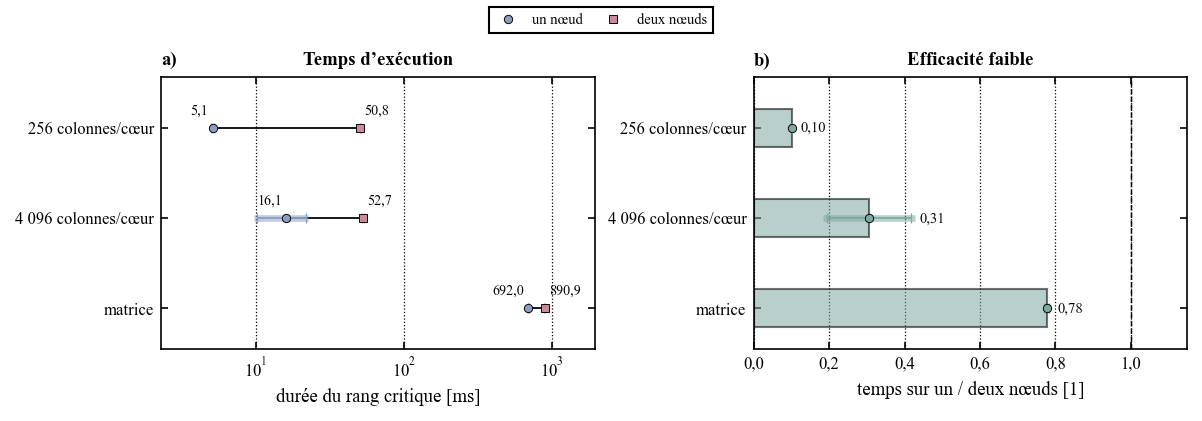

In [17]:
# Comparaison à charge constante par cœur sur un et deux nœuds.
wk_cases = ["pair_256", "pair_4096", "matrix"]
wk_repeat = nv_csv(RES / "mpi/scaling/trials.csv")
wk_repeat = wk_repeat[wk_repeat.study.eq("weak")]
assert wk_repeat.groupby(["case", "nodes"]).block.nunique().eq(7).all()
assert wk_repeat.physical_cores.eq(192 * wk_repeat.nodes).all()
wk_pair = wk_repeat.pivot(index=["case", "block"], columns="nodes", values="seconds")
wk_paired = (wk_pair[1] / wk_pair[2]).droplevel("block")
wk_fig, wk_ax = plt.subplots(1, 2, figsize=(7.9, 2.7))
wk_names = ["256 colonnes/cœur", "4 096 colonnes/cœur", "matrice"]
for wk_row, wk_case in enumerate(wk_cases):
    wk_entries = []
    for wk_i, wk_n in enumerate([1, 2]):
        wk_vals = wk_repeat[wk_repeat.case.eq(wk_case) & wk_repeat.nodes.eq(wk_n)].seconds * 1000
        wk_rec = nv_stats.add(16, "milliseconds", str(wk_n), wk_case, wk_vals, "independent_mpirun")
        wk_entries.append((wk_rec, COLORS[wk_i], "os"[wk_i], ["un nœud", "deux nœuds"][wk_i]))
    comparison(wk_ax[0], wk_row, wk_entries, digits=1)
    wk_rat = nv_stats.add(16, "ratio", "1/2", wk_case, wk_paired.loc[wk_case], "paired_mpirun_block")
    wk_ax[1].barh(wk_row, wk_rat["mean"], height=0.42, color=COLORS[2], alpha=0.55, edgecolor=INK)
    estimate(wk_ax[1], wk_row, wk_rat, COLORS[2], horizontal=True)
    value_label(wk_ax[1], wk_rat["high95"], wk_row, wk_rat["mean"], 2, horizontal=True)
wk_ax[0].set_xscale("log")
category_rows(wk_ax[0], wk_names, "durée du rang critique [ms]")
category_rows(wk_ax[1], wk_names, "temps sur un / deux nœuds [1]")
wk_ax[1].axvline(1, **GUIDE)
label_panels(wk_ax)
column_titles(wk_ax, ("Temps d’exécution", "Efficacité faible"))
legend_above(wk_fig, wk_ax, ncol=3)
nv_save(wk_fig, "distributed/mpi_faible")

*Figure 16.* Chaque marqueur de durée résume sept lancements MPI indépendants, chacun après deux calculs de chauffe. L’ordre des configurations change à chaque bloc. Le rapport sur un et deux nœuds est calculé à l’intérieur du bloc avant la moyenne et l’IC.

<sub>Code : [bench/mpi/scaling.py](../bench/mpi/scaling.py), [bench/mpi/mpi_weak.py](../bench/mpi/mpi_weak.py), [results/mpi/scaling/trials.csv](../results/mpi/scaling/trials.csv).</sub>

La charge par cœur reste constante lorsque le second nœud s’ajoute au premier. L’efficacité moyenne de la matrice vaut 0,777 (écart-type 0,008, IC 95 % de 0,770 à 0,784). La matrice multiplie le nombre de paires entières distribuées. Pour une paire isolée, chaque rang communique à chaque ligne, même dans le cas des 256 colonnes par cœur.

La distance entre deux assemblages humains fournit ensuite un cas où la taille de l’entrée domine.

<p><strong><u>Synthèse.</u></strong> Le passage de 192 à 384 cœurs favorise davantage la matrice que chacune des paires isolées.<br>Cette comparaison dépend de la géométrie et de l’interconnexion des nœuds alloués.</p>

<a id="chromosome"></a>

## Distances entre assemblages d’un chromosome humain

<hr>

La figure 17 compare le temps et la mémoire nécessaires à l’alignement de deux assemblages du chromosome humain.

Le contrôle par insertions donne $d\geq |n-m|=64$. La liste des 64 insertions fournit la borne opposée. Les fenêtres naturelles utilisent des paires d’intervalles orientés dans le même sens et désignés par les coordonnées du manifeste. [Nurk et coll., 2022](https://doi.org/10.1126/science.abj6987)

La chaîne de correspondance de hg38 vers hs1 permet de retrouver dans l’assemblage T2T-CHM13 les bornes de deux intervalles du chromosome 21 de GRCh38. Les positions sont indexées depuis zéro et la borne de fin est exclue. Les fenêtres GRCh38 commencent toutes les deux à 34 000 000 et se terminent à 36 000 000 et 38 000 000. La première est donc incluse dans la seconde. La chaîne sert à choisir les intervalles, puis chaque algorithme calcule une distance globale sur les chaînes FASTA complètes de la paire. [Manifeste et coordonnées](../results/human/manifest.tsv) · [Chaîne de correspondance UCSC](https://hgdownload.soe.ucsc.edu/goldenPath/hg38/liftOver/hg38ToHs1.over.chain.gz)

Le contrôle utilise le chromosome 21 entier de T2T-CHM13, long de 45 090 682 bases, face à une copie où le générateur insère 64 lettres.

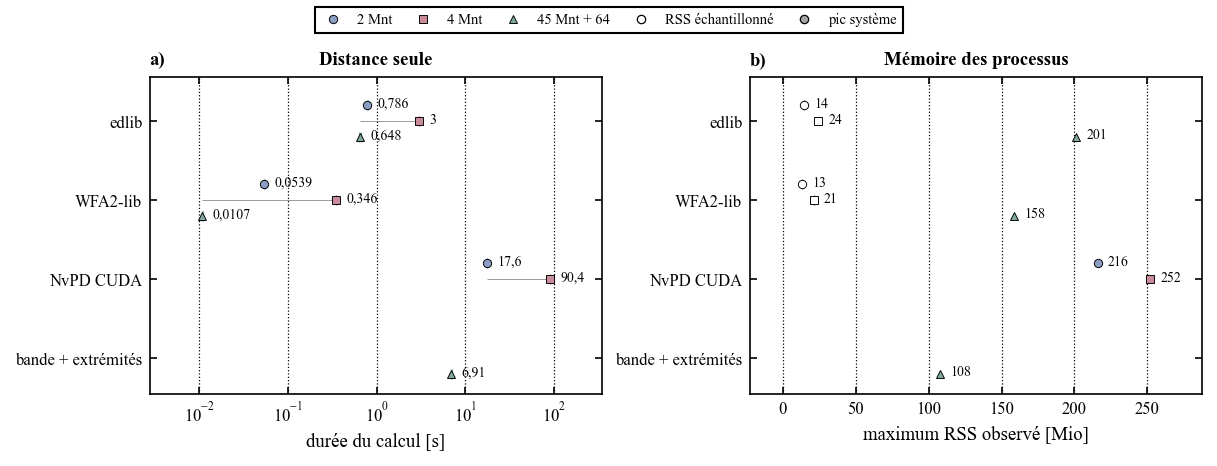

In [18]:
# Intervalles homologues et contrôle synthétique sur fond de chromosome réel.
hu_manifest = pd.read_csv(RES / "human/manifest.tsv", sep="\t").set_index("case")
hu_rep = nv_csv(RES / "repeated/gh200/trials.csv")
hu_ok = hu_rep[hu_rep.warmup.eq(0) & hu_rep.case.isin(hu_manifest.index)].copy()
hu_ok = hu_ok.rename(columns={"process_peak_rss_kib": "peak_rss_kib"})
assert hu_ok.groupby(["case", "algorithm"]).block.nunique().ge(5).all()
assert hu_ok.groupby("case").distance.nunique().eq(1).all()
assert hu_ok.input_sha256.eq(hu_ok.case.map(hu_manifest.sha256)).all()
assert (hu_ok.m == hu_ok.case.map(hu_manifest.m)).all() and (
    hu_ok.n == hu_ok.case.map(hu_manifest.n)
).all()
assert hu_ok.loc[hu_ok.case.eq("chr21-full-insert64"), "distance"].eq(64).all()
hu_spot = pd.read_json(RES / "kokkos/human.json", typ="series")
assert (
    hu_spot.distance
    == hu_spot.reference_distance
    == hu_ok.loc[hu_ok.case.eq("chr21-2m"), "distance"].iloc[0]
)
assert hu_spot.input_sha256 == hu_manifest.loc["chr21-2m", "sha256"]
hu_order = ["chr21-2m", "chr21-4m", "chr21-full-insert64"]
hu_memory = nv_csv(RES / "repeated/gh200/memory_trials.csv")
hu_memory = hu_memory[hu_memory.case.isin(hu_order)]
assert hu_memory.input_sha256.eq(hu_memory.case.map(hu_manifest.sha256)).all()
assert not hu_memory.duplicated(["case", "algorithm", "block"]).any()
hu_fig, hu_ax = plt.subplots(1, 2, figsize=(8.0, 3.0))
hu_methods = [
    ("edlib", "edlib"),
    ("wfa2", "WFA2-lib"),
    ("nvpd-cuda", "NvPD CUDA"),
    ("banded-trim", "bande + extrémités"),
]
hu_shapes = ["2 Mnt", "4 Mnt", "45 Mnt + 64"]
for hu_j, (hu_key, hu_factor, hu_metric) in enumerate(
    [("seconds", 1, "seconds"), ("peak_rss_kib", 1 / 1024, "rss_mib")]
):
    for hu_i, (hu_alg, hu_name) in enumerate(hu_methods):
        hu_points = []
        for hu_k, hu_case in enumerate(hu_order):
            hu_obs = hu_ok[hu_ok.algorithm.eq(hu_alg) & hu_ok.case.eq(hu_case)]
            if not len(hu_obs):
                continue
            hu_sampled = False
            if hu_j == 1:
                hu_mem = hu_memory[hu_memory.case.eq(hu_case) & hu_memory.algorithm.eq(hu_alg)]
                assert len(hu_mem) == len(hu_obs) and hu_mem.rss_kib.gt(0).all()
                assert hu_mem.rss_metric.nunique() == 1
                hu_unit = str(hu_mem.rss_metric.iloc[0])
                hu_sampled = "smaps" in hu_unit
                hu_values = hu_mem.rss_kib / 1024
            else:
                hu_unit = "fresh_process"
                hu_values = hu_obs[hu_key] * hu_factor
            hu_rec = nv_stats.add(17, hu_metric, hu_alg, hu_case, hu_values, hu_unit)
            estimate(
                hu_ax[hu_j],
                hu_i + (hu_k - 1) * 0.20,
                hu_rec,
                COLORS[hu_k],
                marker="os^"[hu_k],
                horizontal=True,
                hollow=hu_sampled,
                label=hu_shapes[hu_k] if hu_j == 0 else None,
            )
            hu_digits = 3 if hu_j == 0 else 1
            hu_value = f"{hu_rec['mean']:.{hu_digits}g}" if hu_j == 0 else f"{hu_rec['mean']:.0f}"
            hu_ax[hu_j].annotate(
                hu_value.replace(".", ","),
                (hu_rec["mean"], hu_i + (hu_k - 1) * 0.20),
                xytext=(5, 1),
                textcoords="offset points",
                va="center",
                fontsize=6.7,
            )
            hu_points.append(hu_rec["mean"])
        if hu_points and hu_j == 0:
            hu_ax[hu_j].hlines(
                hu_i, min(hu_points), max(hu_points), color=INK, linewidth=0.4, alpha=0.45
            )
    if hu_j == 0:
        hu_ax[hu_j].set_xscale("log")
    else:
        hu_ax[hu_j].set_xticks([0, 50, 100, 150, 200, 250])
    category_rows(
        hu_ax[hu_j],
        [item[1] for item in hu_methods],
        ["durée du calcul [s]", "maximum RSS observé [Mio]"][hu_j],
    )
hu_ax[1].plot([], [], ls="none", marker="o", color=INK, markerfacecolor=PAPER, label="RSS échantillonné")
hu_ax[1].plot([], [], ls="none", marker="o", color=INK, markerfacecolor=COLORS[4], label="pic système")
label_panels(hu_ax)
column_titles(hu_ax, ("Distance seule", "Mémoire des processus"))
legend_above(hu_fig, hu_ax, ncol=5)
nv_save(hu_fig, "biology/chromosome21")

*Figure 17.* Sur Grace et GH200, un appel complet chauffe chaque processus avant l’alignement chronométré. Chaque configuration comprend cinq processus. En mémoire, les symboles pleins indiquent le pic getrusage. Les symboles creux indiquent le maximum de relevés smaps_rollup dans une campagne séparée. Le relevé vise une période de 1 ms. Le maximum observé est une borne inférieure du pic, car un appel bref peut se terminer entre deux relevés.

<sub>Code : [bench/repeated/kernel.cpp](../bench/repeated/kernel.cpp), [results/human/manifest.tsv](../results/human/manifest.tsv), [results/repeated/gh200/trials.csv](../results/repeated/gh200/trials.csv), [results/kokkos/human.json](../results/kokkos/human.json), [results/repeated/gh200/memory_trials.csv](../results/repeated/gh200/memory_trials.csv), [bench/repeated/memory/grace_memory.py](../bench/repeated/memory/grace_memory.py).</sub>

Les fenêtres de deux et quatre millions de bases ont des distances respectives de 5 599 et 12 482. Leurs portées maximales de 290 et 622 colonnes imposent le noyau NvPD par ligne. Sur la fenêtre de 4 Mnt, NvPD CUDA prend 90,42 (écart-type 0,28, IC 95 % de 90,08 à 90,76) s et WFA2-lib 0,346 s. Kokkos CUDA atteint le même score de 5 599 dans son contrôle séparé à 24,20 s. Cette observation unique porte sur une autre allocation et un autre environnement de compilation.

Lorsque les deux séquences diffèrent peu, restreindre les états explorés peut réduire le travail.

<p><strong><u>Synthèse.</u></strong> Le témoin sur chromosome entier comporte exactement 64 insertions contrôlées.<br>Sa faible distance et sa longueur distinguent le coût lié aux différences du coût lié à la taille.</p>

<a id="assemblages-entiers"></a>

## Comparaison de chromosomes humains entiers

<hr>

La figure 18 compare les temps de calcul du chromosome 20 et les bornes disponibles pour la distance entre les deux références du chromosome 21.

Pour la lettre $c$, $s_a=\sum_c\max(h_a(c)-h_b(c),0)$ compte les excédents de $a$, et $s_b$ ceux de $b$. Chaque édition résout au plus un excédent de chaque côté. Ainsi $\max(s_a,s_b)\leq d(a,b)$. Une chaîne de correspondance monotone entre les assemblages fournit un alignement explicite de coût $U$, donc $d(a,b)\leq U$.

Les séquences CP068258.1 et CP068258.2 représentent les versions 1.0 et 2.0 du chromosome 20 de T2T-CHM13. Les longueurs valent 66 210 247 et 66 210 255 bases. Sur le chromosome 21, GRCh38 et CHM13 mesurent respectivement 46 709 983 et 45 090 682 bases. Le programme aligne les chaînes déposées, avec un coût unitaire et une comparaison littérale des symboles ambigus. Le chromosome 20 est chronométré sur le processeur Grace, à raison de cinq processus indépendants par bibliothèque et d’une chauffe par processus. Pour le chromosome 21, une tentative par méthode sur un cœur EPYC dispose de 120 s et de 4 Gio d’espace d’adressage.

Le consortium T2T décrit la validation et le polissage des assemblages CHM13. La comparaison entre versions porte ainsi sur deux représentations du même échantillon. [Mc Cartney et coll., 2022](https://doi.org/10.1038/s41592-022-01440-3)

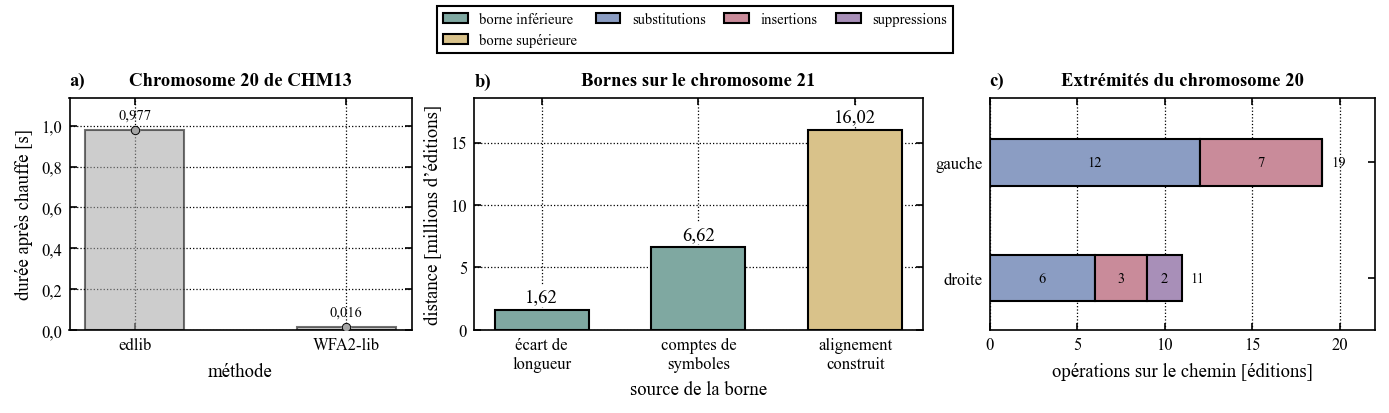

In [19]:
# Calcul terminé ou observation censurée sur les deux chromosomes entiers.
wh_raw = nv_csv(RES / "human/whole/838443/trials.csv")
wh_manifest = pd.read_csv(RES / "human/whole/manifest.tsv", sep="\t").set_index("case")
assert wh_raw.input_sha256.eq(wh_raw.case.map(wh_manifest.sha256)).all()
wh_bounds = nv_csv(RES / "human/whole/bounds.csv").iloc[0]
assert wh_bounds.lower == max(wh_bounds.surplus_a, wh_bounds.surplus_b)
assert (
    wh_bounds.length_gap == abs(wh_bounds.m - wh_bounds.n)
    and wh_bounds.length_gap <= wh_bounds.lower <= wh_bounds.upper
)
wh_first = wh_raw[wh_raw.case.eq("chr20-assemblies")].copy()
assert wh_first.groupby("method").trial.nunique().eq(3).all()
assert wh_first.status.eq("ok").all() and pd.to_numeric(wh_first.distance).eq(30).all()
wh_first["seconds"] = pd.to_numeric(wh_first.seconds)
wh_second = wh_raw[wh_raw.case.eq("chr21-assemblies")].set_index("method")
wh_order = ["edlib", "wfa2"]
wh_labels = ["edlib", "WFA2-lib"]
wh_fig, wh_ax = plt.subplots(1, 3, figsize=(9.15, 2.65), width_ratios=[0.87, 1.14, 0.98])
wh_x = np.arange(2)
wh_hot = nv_csv(RES / "repeated/gh200/trials.csv")
wh_hot = wh_hot[wh_hot.warmup.eq(0) & wh_hot.case.eq("chr20-assemblies")]
assert wh_hot.groupby("algorithm").block.nunique().ge(5).all() and wh_hot.distance.eq(30).all()
for wh_xi, wh_alg in enumerate(wh_order):
    wh_values = wh_hot[wh_hot.algorithm.eq(wh_alg)].seconds
    wh_stats = nv_stats.add(18, "seconds", wh_alg, "chr20", wh_values, "fresh_process")
    wh_ax[0].bar(wh_xi, wh_stats["mean"], width=0.47, color=COLORS[4], alpha=0.55, edgecolor=INK)
    estimate(wh_ax[0], wh_xi, wh_stats, COLORS[4])
    value_label(wh_ax[0], wh_xi, wh_stats["high95"], wh_stats["mean"], 3)
wh_ax[0].set(ylabel="durée après chauffe [s]", xticks=[0, 1], xticklabels=wh_labels, xlabel="méthode")
wh_ax[0].margins(y=0.16)
wh_limits = [wh_bounds.length_gap, wh_bounds.lower, wh_bounds.upper]
wh_names = ["écart de\nlongueur", "comptes de\nsymboles", "alignement\nconstruit"]
for wh_idx, wh_count in enumerate(wh_limits):
    wh_low = wh_idx < 2
    wh_height = wh_count / 1e6
    wh_ax[1].bar(
        wh_idx,
        wh_height,
        width=0.60,
        color=COLORS[2 if wh_low else 3],
        edgecolor=INK,
        label="borne inférieure" if wh_low else "borne supérieure",
    )
    wh_ax[1].annotate(
        f"{wh_height:.2f}".replace(".", ","),
        (wh_idx, wh_height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        bbox=dict(facecolor=PAPER, edgecolor=PAPER, pad=0.3),
    )
wh_ax[1].set_xticks(range(3), wh_names)
wh_ax[1].set(
    ylabel="distance [millions d’éditions]",
    xlabel="source de la borne",
    ylim=(0, 1.16 * max(wh_limits) / 1e6),
)
assert wh_second.status.eq("wall_limit_120s").all()
wh_edits = pd.read_csv(RES / "human/whole/chr20-edits.tsv", sep="\t")
wh_gaps = wh_edits.start_a.to_numpy()[1:] - wh_edits.end_a.to_numpy()[:-1]
wh_cut = int(np.argmax(wh_gaps)) + 1
wh_long = int(wh_gaps[wh_cut - 1])
assert wh_edits.length.sum() == 30 and len(wh_edits) == 27
assert wh_long == 66_209_720
assert wh_edits.start_b.iloc[wh_cut] - wh_edits.end_b.iloc[wh_cut - 1] == wh_long
wh_offset = np.zeros(2)
wh_operation_colors = [COLORS[0], COLORS[1], COLORS[5]]
for wh_i, (wh_op, wh_name) in enumerate(
    [("X", "substitutions"), ("I", "insertions"), ("D", "suppressions")]
):
    wh_counts = [
        wh_part.loc[wh_part.operation.eq(wh_op), "length"].sum()
        for wh_part in [wh_edits.iloc[:wh_cut], wh_edits.iloc[wh_cut:]]
    ]
    wh_ax[2].barh(
        [0, 1],
        wh_counts,
        left=wh_offset,
        height=0.4,
        color=wh_operation_colors[wh_i],
        edgecolor=INK,
        label=wh_name,
    )
    for wh_j, wh_count in enumerate(wh_counts):
        if wh_count:
            wh_ax[2].text(
                wh_offset[wh_j] + wh_count / 2, wh_j, str(wh_count), ha="center", va="center", fontsize=7
            )
        nv_stats.add(
            18,
            "edits_" + wh_op,
            "optimal_path",
            ["left", "right"][wh_j],
            [wh_count],
            "alignment_path",
            independent=False,
        )
    wh_offset += wh_counts
category_rows(wh_ax[2], ["gauche", "droite"], "opérations sur le chemin [éditions]")
for wh_j, wh_count in enumerate(wh_offset):
    value_label(wh_ax[2], wh_count, wh_j, wh_count, 0, horizontal=True)
wh_ax[2].set_xlim(0, 22)
label_panels(wh_ax)
column_titles(
    wh_ax, ("Chromosome 20 de CHM13", "Bornes sur le chromosome 21", "Extrémités du chromosome 20")
)
legend_above(wh_fig, wh_ax, ncol=4)
nv_save(wh_fig, "biology/chromosomes_entiers")

*Figure 18.* Le chromosome 20 est mesuré sur Grace dans cinq processus indépendants par bibliothèque, après un alignement de chauffe. Les trois bornes du chromosome 21 sont déterministes. Les deux calculs plafonnés à 120 s se sont achevés sans score. Le panneau c) donne l’effectif de chaque opération dans le chemin optimal du chromosome 20, de part et d’autre du plus long segment identique.

<sub>Code : [bench/human/whole_chromosomes.py](../bench/human/whole_chromosomes.py), [results/human/whole/manifest.tsv](../results/human/whole/manifest.tsv), [results/human/whole/838443/trials.csv](../results/human/whole/838443/trials.csv), [bench/human/chromosome_bounds.py](../bench/human/chromosome_bounds.py), [results/human/whole/bounds.csv](../results/human/whole/bounds.csv), [results/repeated/gh200/trials.csv](../results/repeated/gh200/trials.csv), [results/human/whole/chr20-edits.tsv](../results/human/whole/chr20-edits.tsv), [bench/human/assembly_edits.py](../bench/human/assembly_edits.py).</sub>

Les deux versions de CHM13 donnent une distance globale de 30 sur le chromosome 20. Sur Grace, le calcul WFA2-lib prend 0,016 (écart-type 0,000, IC 95 % de 0,016 à 0,017) s en moyenne. Les 27 segments non identiques du chemin rejoué comprennent 19 éditions à gauche et 11 à droite. Le segment central de 66 209 720 correspondances couvre 99,9992 % du premier assemblage. Cette distribution décrit le chemin entre deux versions de CHM13. Sur le chromosome 21 entre GRCh38 et CHM13, les deux processus atteignent la limite de 120 s. Le déséquilibre des comptes de symboles impose une borne inférieure plus élevée que la seule différence de longueur. Le coût du chemin construit fournit la borne supérieure.

Les méthodes sensibles au score permettent d’examiner comment la position des différences intervient.

<p><strong><u>Synthèse.</u></strong> Pour le chromosome 21, la distance reste comprise entre 6 621 364 et 16 015 052 éditions.<br>Les deux observations plafonnées donnent seulement une information de censure pour la durée.</p>

<a id="methodes-distance"></a>

## Méthodes exactes sensibles à la distance

<hr>

La figure 19 examine la réduction du temps de calcul lorsque les erreurs se concentrent dans une bande ou dans un intervalle court.

La bande adaptative cherche d’abord un chemin de faible coût dans un couloir autour de la diagonale. Si le seuil est insuffisant, elle élargit le couloir jusqu’à obtenir un score inférieur ou égal au seuil. La variante `banded-trim` supprime aussi le préfixe et le suffixe communs avant ce calcul. En distance d’édition unitaire, deux lettres terminales identiques peuvent être appariées gratuitement. Supprimer ces extrémités conserve donc le score. Pour un seuil $k$, un chemin dont le coût est inférieur ou égal à $k$ reste dans $|i-j|\leq k$. L’implémentation double $k$ après chaque essai infructueux. Le temps gagné par le retrait des extrémités dépend de leur longueur. [Ukkonen, recherche à seuil](https://doi.org/10.1016/S0019-9958%2885%2980046-2)

Les deux allocations emploient un cœur du même nœud EPYC. Les deux méthodes en bande utilisent le second banc, avec edlib et WFA2-lib comme témoins. Les autres méthodes viennent du premier banc. Chaque bloc lance un processus par méthode, chauffe la paire puis mesure dix appels. Les deux modes Rust d’A*PA2 rendent également le chemin. Les écarts entre allocations peuvent peser sur les comparaisons entre familles.

QuickEd, de Doblas et coll., estime une borne de coût avant de reconstruire un alignement en bande. A*PA2, de Groot Koerkamp, associe programmation dynamique bit-parallèle, élargissement de bande et guidage heuristique. Ding et coll. proposent une autre famille d’algorithmes parallèles dont le travail dépend de la distance. La figure compare A*PA2 simple et complet aux cinq autres configurations sur les mêmes entrées. Les résultats de Ding et coll. restent bibliographiques. Sassy, de R. Beeloo et R. Groot Koerkamp, recherche les occurrences approchées d’un motif dans un texte. Le programme mm2-plus accélère le placement et l’alignement de segments par minimap2, une tâche différente du calcul d’un unique score global exact. [QuickEd, 2025](https://doi.org/10.1093/bioinformatics/btaf112) · [A*PA2, 2024](https://doi.org/10.4230/LIPIcs.WABI.2024.17) · [Ding et coll., 2023](https://doi.org/10.4230/LIPIcs.ESA.2023.40) · [Sassy, 2026](https://doi.org/10.1093/bioinformatics/btag244) · [mm2-plus, 2026](https://doi.org/10.1093/bioinformatics/btag083)

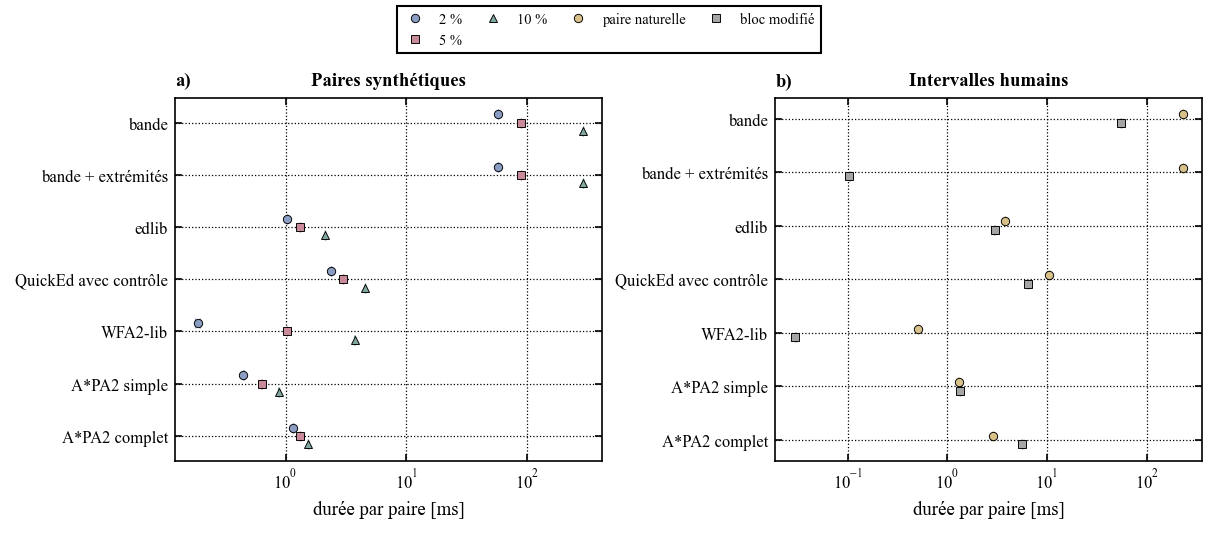

In [20]:
# Essais des méthodes exactes à entrée et machine identiques.
al_root = RES / "alternatives/romeo/838762"
al_cases_observed = nv_csv(al_root / "cases.csv").set_index("case")
al_valid = ["20k-0.02", "20k-0.05", "20k-0.1", "chr21-50k", "chr21-center128"]
al_ext = nv_csv(al_root / "trials.csv")
al_ext = al_ext[al_ext.case.isin(al_valid) & al_ext.variant.ne("quicked-stock")]
assert al_ext.correct.eq(1).all() and al_ext.exact.eq(al_ext.case.map(al_cases_observed.exact)).all()
al_bridge = nv_csv(RES / "repeated/epyc-bands/trials.csv")
al_bridge = al_bridge[al_bridge.warmup.eq(0)]
assert al_bridge.input_sha256.eq(al_bridge.case.map(al_cases_observed.sha256)).all()
assert al_bridge.distance.eq(al_bridge.case.map(al_cases_observed.exact)).all()
assert al_bridge.groupby(["case", "algorithm", "block"]).call.nunique().eq(10).all()
assert al_ext.groupby(["case", "variant", "block"]).call.nunique().eq(10).all()
al_ext = al_ext.groupby(["case", "variant", "block"], as_index=False).seconds.mean()
al_band = al_bridge[al_bridge.algorithm.isin(["banded", "banded-trim"])].rename(
    columns={"algorithm": "variant"}
)
al_band = al_band.groupby(["case", "variant", "block"], as_index=False).seconds.mean()
al_ok = pd.concat([al_ext, al_band], ignore_index=True)
assert al_ok.groupby(["case", "variant"]).block.nunique().eq(8).all()
assert al_ok.groupby("case").variant.nunique().eq(7).all()
al_fig, al_ax = plt.subplots(1, 2, figsize=(8.0, 3.45))
al_methods = {
    "banded": "bande",
    "banded-trim": "bande + extrémités",
    "edlib": "edlib",
    "quicked-certified": "QuickEd avec contrôle",
    "wfa2": "WFA2-lib",
    "astarpa2-simple": "A*PA2 simple",
    "astarpa2-full": "A*PA2 complet",
}
al_scenarios = [("20k-0.02", "2 %"), ("20k-0.10", "10 %")]
al_lists = [
    [("20k-0.02", "2 %"), ("20k-0.05", "5 %"), ("20k-0.1", "10 %")],
    [("chr21-50k", "paire naturelle"), ("chr21-center128", "bloc modifié")],
]
for al_i, al_scenarios in enumerate(al_lists):
    for al_j, (al_case, al_label) in enumerate(al_scenarios):
        al_points = al_ok[al_ok.case.eq(al_case)].set_index("variant").seconds * 1000
        nv_plot(
            al_ax[al_i],
            al_points,
            list(al_methods),
            np.arange(7) + 0.16 * (al_j - (len(al_scenarios) - 1) / 2),
            19,
            "milliseconds",
            al_case,
            "independent_process_mean_10_calls",
            COLORS[al_j if al_i == 0 else al_j + 3],
            "os^"[al_j],
            horizontal=True,
            label=al_label,
        )
    al_ax[al_i].set(
        yticks=range(7), yticklabels=al_methods.values(), xscale="log", xlabel="durée par paire [ms]"
    )
    al_ax[al_i].invert_yaxis()
al_port = nv_csv(RES / "alternatives/wfa-portability/838814/trials.csv")
assert al_port.groupby(["case", "variant", "block"]).call.nunique().eq(10).all()
assert al_port.groupby("case").score.nunique().eq(1).all()
al_runmean = al_port.groupby(["case", "block", "variant"]).seconds.mean().unstack()
for al_case, al_run in al_runmean.groupby("case"):
    al_port_ratio = al_run.portable / al_run.stock
    nv_stats.add(
        19,
        "separate_portability_ratio",
        "WFA2 portable/stock",
        al_case,
        al_port_ratio,
        "paired_process_block",
    )
label_panels(al_ax)
column_titles(al_ax, ("Paires synthétiques", "Intervalles humains"))
legend_above(al_fig, al_ax, ncol=4)
nv_save(al_fig, "comparison/methodes_exactes")

*Figure 19.* À gauche, les sept variantes sont évaluées sur trois entrées synthétiques de 20 knt. À droite, elles traitent deux intervalles du chromosome 21. Chaque point résume huit processus préchauffés sur EPYC, chacun fournissant une moyenne de dix appels. Les durées restent séparées par méthode et entrée.

<sub>Code : [results/alternatives/romeo/838762/trials.csv](../results/alternatives/romeo/838762/trials.csv), [results/repeated/epyc-bands/trials.csv](../results/repeated/epyc-bands/trials.csv), [results/alternatives/romeo/838762/cases.csv](../results/alternatives/romeo/838762/cases.csv), [results/alternatives/wfa-portability/838814/trials.csv](../results/alternatives/wfa-portability/838814/trials.csv), [results/alternatives/wfa-portability/838814/machine-code.csv](../results/alternatives/wfa-portability/838814/machine-code.csv).</sub>

Les sept configurations fournissent les mêmes coûts sur les cinq entrées communes sur EPYC. Sur l’intervalle naturel de 50 knt, WFA2-lib demande 0,507 (écart-type 0,006, IC 95 % de 0,503 à 0,512) ms. A*PA2 simple y prend 1,297 ms et restitue également le chemin. Pour la modification centrale sur 100 knt, le retrait des extrémités abaisse la moyenne de 54,66 à 0,104 ms. Les durées principales de WFA2-lib proviennent de la version amont épinglée. Une seconde allocation mesure la version portable du dépôt, avec des lectures par memcpy. Sous GCC 11, le code machine du noyau d’extension est identique à celui de l’amont. Sur les cinq entrées, les IC des rapports appariés incluent 1.

Chaque coût ainsi vérifié peut devenir une entrée d’une matrice de distances entre génomes.

<p><strong><u>Synthèse.</u></strong> Sur l’intervalle naturel de 50 knt, les sept configurations concordent sur le score de 698.<br>L’emplacement des différences peut rendre le retrait d’extrémités plus intéressant que l’élargissement de la bande.</p>

<a id="certification-quicked"></a>

## Justesse et coût de la certification de QuickEd

<hr>

La figure 20 compare le score de QuickEd 1.2 à un témoin exact, puis mesure le temps de calcul avec contrôle du chemin.

Un alignement restreint à une bande peut exclure un chemin optimal. Sur le témoin périodique de 512 lettres, limiter les décalages à 63 impose un coût de 133. Une largeur de 64 permet le coût global de 128. Un défaut distinct touche le parcours inverse du code amont QuickEd sur certaines répétitions décalées. Sur les deux témoins du M1, l’instrumentation observe un indice de bit de $-1$ au bord de la bande alors que la borne de coût vaut déjà 128. Deux gardes vérifient désormais les limites du bloc. Le pilote compare le résultat au score d’edlib, élargit la bande en cas de désaccord et restitue le score exact si le désaccord persiste. Le résidu tracé est $e=d_{reported}-d_{exact}$. Une erreur nulle signifie que les deux scores concordent sur l’entrée testée. [QuickEd, Doblas et coll.](https://doi.org/10.1093/bioinformatics/btaf112)

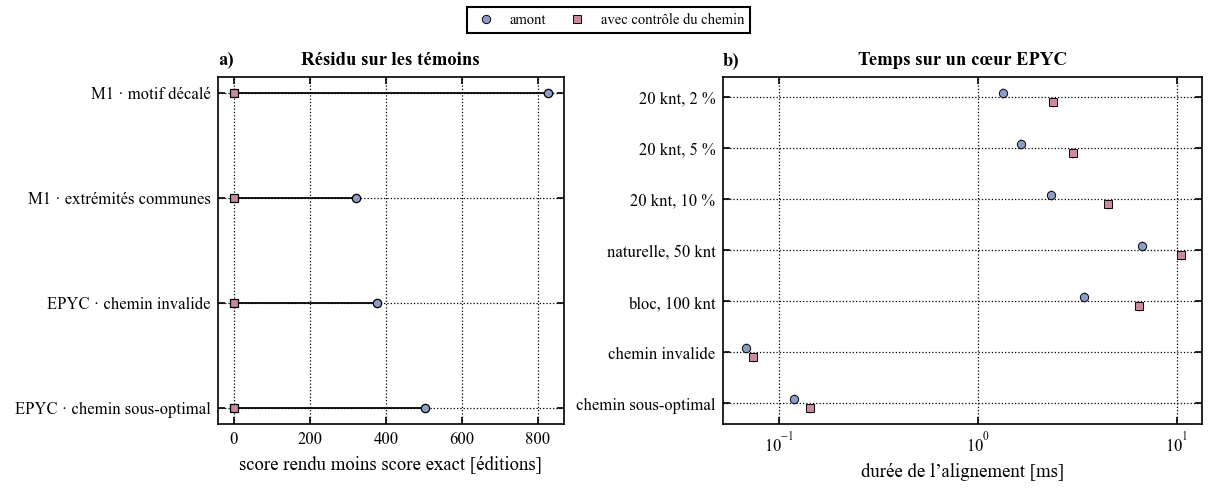

In [21]:
# Même entrée et même plateforme à l'intérieur de chaque comparaison.
qe_root = RES / "alternatives/romeo/838762"
qe_raw = nv_csv(qe_root / "trials.csv")
qe_cases = nv_csv(qe_root / "cases.csv").set_index("case")
qe_m1 = nv_csv(RES / "alternatives/diagnosis/correctness-m1.csv")
qe_sub = qe_raw[qe_raw.variant.str.startswith("quicked-")].copy()
assert qe_sub.exact.eq(qe_sub.case.map(qe_cases.exact)).all()
assert qe_sub.groupby(["case", "variant", "block"]).call.nunique().eq(10).all()
assert qe_sub.groupby(["case", "variant"]).block.nunique().eq(8).all()
assert qe_sub[qe_sub.variant.eq("quicked-certified")].correct.eq(1).all()
qe_x86 = qe_sub.groupby(["case", "variant"], as_index=False)[["score", "exact"]].first()
assert qe_sub.groupby(["case", "variant"]).score.nunique().eq(1).all()
qe_fig, qe_ax = plt.subplots(1, 2, figsize=(8.0, 3.2), width_ratios=[0.9, 1.25])
qe_witness = [
    ("M1", "periodic512", "motif décalé"),
    ("M1", "periodic256-tail", "extrémités communes"),
    ("EPYC", "native-impossible", "chemin invalide"),
    ("EPYC", "native-suboptimal", "chemin sous-optimal"),
]
for qe_i, (qe_host, qe_key, qe_short) in enumerate(qe_witness):
    qe_scores = qe_m1 if qe_host == "M1" else qe_x86
    qe_scores = qe_scores[qe_scores.case.eq(qe_key)].set_index("variant")
    qe_error = qe_scores.score - qe_scores.exact
    for qe_j, qe_var in enumerate(["quicked-stock", "quicked-certified"]):
        qe_val = float(qe_error.loc[qe_var])
        nv_stats.add(
            20,
            "score_error",
            qe_var,
            qe_host + "/" + qe_key,
            [qe_val],
            "fixed_witness",
            independent=False,
        )
        qe_ax[0].plot(
            qe_val,
            qe_i,
            marker="os"[qe_j],
            color=COLORS[qe_j],
            markeredgecolor=INK,
            label=["amont", "avec contrôle du chemin"][qe_j],
            zorder=3,
        )
    join(
        qe_ax[0],
        [qe_i, qe_i],
        qe_error.reindex(["quicked-stock", "quicked-certified"]),
        INK,
        horizontal=True,
    )
qe_ax[0].set(
    yticks=range(4),
    yticklabels=[qe_item[0] + " · " + qe_item[2] for qe_item in qe_witness],
    xlabel="score rendu moins score exact [éditions]",
)
qe_ax[0].invert_yaxis()
qe_groups = qe_sub.groupby(["case", "variant", "block"], as_index=False).seconds.mean()
qe_order = [
    "20k-0.02",
    "20k-0.05",
    "20k-0.1",
    "chr21-50k",
    "chr21-center128",
    "native-impossible",
    "native-suboptimal",
]
qe_labels = [
    "20 knt, 2 %",
    "20 knt, 5 %",
    "20 knt, 10 %",
    "naturelle, 50 knt",
    "bloc, 100 knt",
    "chemin invalide",
    "chemin sous-optimal",
]
for qe_j, qe_var in enumerate(["quicked-stock", "quicked-certified"]):
    qe_time = qe_groups[qe_groups.variant.eq(qe_var)].set_index("case").seconds * 1000
    nv_plot(
        qe_ax[1],
        qe_time,
        qe_order,
        np.arange(len(qe_order)) + (qe_j - 0.5) * 0.18,
        20,
        "ms",
        qe_var,
        "independent_process_mean_10_calls",
        COLORS[qe_j],
        "os"[qe_j],
        horizontal=True,
        label=["amont", "avec contrôle du chemin"][qe_j],
    )
qe_ax[1].set(
    xscale="log", xlabel="durée de l’alignement [ms]", yticks=range(len(qe_order)), yticklabels=qe_labels
)
qe_ax[1].invert_yaxis()
label_panels(qe_ax)
column_titles(qe_ax, ("Résidu sur les témoins", "Temps sur un cœur EPYC"))
legend_above(qe_fig, qe_ax, ncol=2)
nv_save(qe_fig, "comparison/quicked")

*Figure 20.* À gauche, chaque segment relie deux scores déterministes obtenus sur la plateforme indiquée. À droite, chaque configuration EPYC a huit processus indépendants avec une chauffe et dix appels mesurés par processus. Les durées amont sont conservées même si le score s’écarte de l’oracle sur un témoin.

<sub>Code : [src/libraries/quicked/quicked_adapter.c](../src/libraries/quicked/quicked_adapter.c), [results/alternatives/diagnosis/correctness-m1.csv](../results/alternatives/diagnosis/correctness-m1.csv), [results/alternatives/romeo/838762/trials.csv](../results/alternatives/romeo/838762/trials.csv), [results/alternatives/romeo/838762/cases.csv](../results/alternatives/romeo/838762/cases.csv), [results/alternatives/romeo/838762/trace.csv](../results/alternatives/romeo/838762/trace.csv), [results/alternatives/diagnosis/fixed-band.csv](../results/alternatives/diagnosis/fixed-band.csv), [results/alternatives/diagnosis/trace-m1.csv](../results/alternatives/diagnosis/trace-m1.csv).</sub>

Sur EPYC, le programme amont donne 506 au lieu de 128 sur un témoin et 760 au lieu de 256 sur l’autre. Les deux cas qui échouent sur M1 donnent des scores exacts dans ce binaire EPYC. Sur la paire naturelle de 50 knt, le calcul avec contrôle du chemin demande 10,436 (écart-type 0,009, IC 95 % de 10,428 à 10,443) ms. La durée inclut le contrôle des indices et le rejeu du chemin. Le nombre de contrôles réussis décrit les entrées mesurées et les appels rejoués.

Les distances exactes peuvent ensuite servir à construire une matrice pour une collection.

<p><strong><u>Synthèse.</u></strong> Le calcul avec contrôle du chemin restitue le score d’edlib pour les dix entrées du jeu EPYC.<br>Les 800 appels chronométrés ne constituent que dix cas de justesse distincts.</p>

<a id="phylogenie"></a>

## Structure des distances entre génomes de phages

<hr>

La figure 21 mesure les écarts aux hypothèses de chaque arbre reconstruit à partir des distances d’édition.

Pour trois feuilles, $g_3=d_{(3)}-d_{(2)}$ est la différence entre les deux plus grandes distances. Un arbre ultramétrique impose $g_3=0$. Pour quatre feuilles, on forme $d_{ij}+d_{kl}$ avec les trois appariements distincts. L’additivité impose l’égalité des deux plus grandes sommes, soit $g_4=0$. Le résidu entre deux feuilles est $r_{ij}=\ell_{ij}-d_{ij}$, où $\ell_{ij}$ est la somme des branches reliant les feuilles.

Chaque matrice contient les 2 016 distances des 64 génomes complets de φX174. Les programmes calculent la distance globale sur les chaînes déposées. Celle-ci dépend de l’origine choisie pour un chromosome circulaire. UPGMA joint les groupes dont la moyenne des distances est minimale et place toutes les feuilles à la même hauteur. Neighbor-Joining utilise les sommes de distances à tous les autres groupes et produit un arbre non enraciné. Les tests portent sur tous les triplets et tous les quartets. [Sokal et Michener, 1958](https://www.biodiversitylibrary.org/part/385476) · [Saitou et Nei, 1987](https://doi.org/10.1093/oxfordjournals.molbev.a040454)

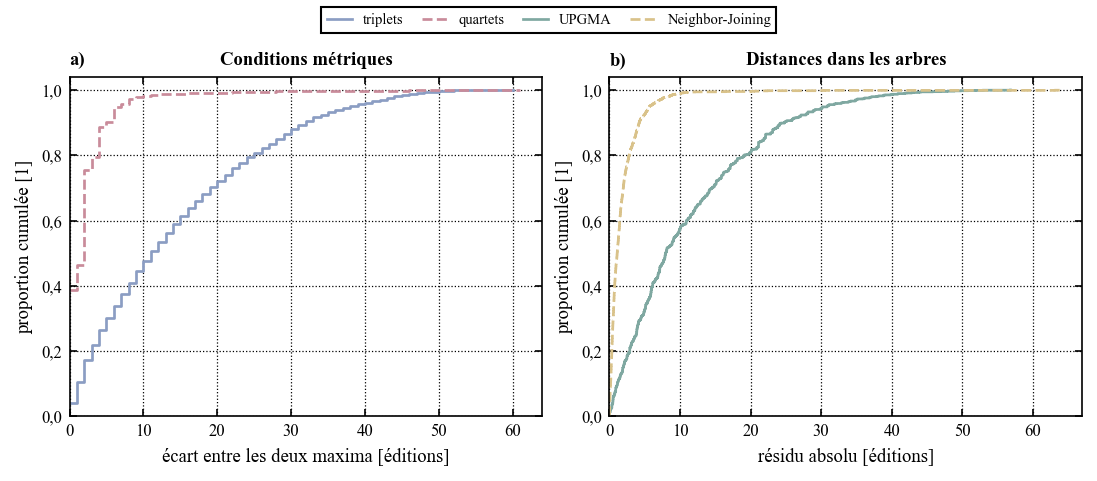

In [22]:
# Écarts aux conditions de distance et résidus de l'ajustement patristique.
phy_dir = RES / "phylogeny/phix174"
phy_gaps = nv_csv(phy_dir / "gaps.csv")
phy_fit = nv_csv(phy_dir / "pair_fit.csv")
assert len(phy_fit) == 2016
assert phy_gaps.groupby("criterion")["count"].sum().to_dict() == {
    "ultrametric": 41664,
    "four_point": 635376,
}
phy_fig, phy_ax = plt.subplots(1, 2, figsize=(7.2, 3.1))
for phy_ix, (phy_key, phy_name) in enumerate([("ultrametric", "triplets"), ("four_point", "quartets")]):
    phy_counts = phy_gaps[phy_gaps.criterion.eq(phy_key)].sort_values("gap")
    phy_ax[0].step(
        phy_counts.gap,
        phy_counts["count"].cumsum() / phy_counts["count"].sum(),
        where="post",
        color=COLORS[phy_ix],
        ls=["-", "--"][phy_ix],
        label=phy_name,
    )
for phy_ix, (phy_col, phy_algorithm) in enumerate(
    [("upgma_path", "UPGMA"), ("nj_path", "Neighbor-Joining")]
):
    phy_abs = np.sort((phy_fit[phy_col] - phy_fit.edit_distance).abs().to_numpy())
    phy_ax[1].step(
        phy_abs,
        np.arange(1, len(phy_abs) + 1) / len(phy_abs),
        where="post",
        color=COLORS[phy_ix + 2],
        ls=["-", "--"][phy_ix],
        label=phy_algorithm,
    )
phy_ax[0].set(xlabel="écart entre les deux maxima [éditions]", ylabel="proportion cumulée [1]")
phy_ax[1].set(xlabel="résidu absolu [éditions]", ylabel="proportion cumulée [1]")
for phy_axis in phy_ax:
    phy_axis.set(xlim=(0, None), ylim=(0, 1.04))
for phy_name, phy_col in [("upgma", "upgma_path"), ("nj", "nj_path")]:
    phy_rmse = np.sqrt(np.mean((phy_fit[phy_col] - phy_fit.edit_distance) ** 2))
    nv_stats.add(
        21, "path_rmse", phy_name, "phix64", [phy_rmse], "complete_distance_matrix", independent=False
    )
label_panels(phy_ax)
column_titles(phy_ax, ("Conditions métriques", "Distances dans les arbres"))
legend_above(phy_fig, phy_ax, ncol=4)
nv_save(phy_fig, "biology/phylogenie")

*Figure 21.* La proportion cumulée de triplets et de quartets donne la distribution des écarts aux deux conditions. Les résidus comparent ensuite la longueur du chemin dans chaque arbre à la distance globale observée entre les mêmes feuilles.

<sub>Code : [scripts/phylogeny/tree.py](../scripts/phylogeny/tree.py), [results/romeo/cohort-837271/matrix.tsv](../results/romeo/cohort-837271/matrix.tsv), [results/romeo/cohort-837271/upgma.nwk](../results/romeo/cohort-837271/upgma.nwk), [results/romeo/cohort-837271/nj.nwk](../results/romeo/cohort-837271/nj.nwk), [results/phylogeny/phix174/gaps.csv](../results/phylogeny/phix174/gaps.csv), [results/phylogeny/phix174/pair_fit.csv](../results/phylogeny/phix174/pair_fit.csv), [results/phylogeny/phix174/fit.csv](../results/phylogeny/phix174/fit.csv), [results/ncbi/phix174.tsv](../results/ncbi/phix174.tsv), [results/phylogeny/phix174/branches.csv](../results/phylogeny/phix174/branches.csv), [results/phylogeny/phix174/duplicate_sensitivity.csv](../results/phylogeny/phix174/duplicate_sensitivity.csv).</sub>

Les distances d’édition entre phages vont de 0 à 134, avec une médiane de 55. Seuls 1 661 des 41 664 triplets satisfont l’égalité ultramétrique. Parmi 635 376 quartets, 245 847 satisfont la condition des quatre points. L’erreur absolue maximale atteint toutefois 56,87 et 63,86 éditions respectivement. Neighbor-Joining réduit ainsi l’erreur moyenne sur ces paires tout en donnant le plus grand écart individuel. Les accessions HM753660.1 et HM753661.1 sont identiques dans la matrice. En retirant une copie, 38 275 des 39 711 triplets et 368 769 des 595 665 quartets présentent encore un écart. Pour chaque arête, la RMSE calculée sur les paires qui la traversent se situe entre 9,62 et 26,63 éditions avec UPGMA et entre 0,98 et 11,98 avec Neighbor-Joining.

Les coûts de calcul et l’ajustement aux distances éclairent le choix de la méthode pour une collection.

<p><strong><u>Synthèse.</u></strong> L’erreur quadratique moyenne des distances patristiques a pour racine 14,89 éditions sous UPGMA et 3,56 sous Neighbor-Joining.<br>La plus grande erreur individuelle reste plus élevée sous Neighbor-Joining sur cette collection.</p>

<a id="groupes-surveillance"></a>

## Concordance avec les groupes de surveillance

<hr>

La figure 22 confronte les distances au sein des groupes de surveillance à leur récupération par les reconstructions d’arbres.

Pour une partition en groupes, le nombre de paires intra-groupes vaut $\sum_g n_g(n_g-1)/2$. Un groupe est retrouvé lorsqu’une arête de longueur positive sépare exactement ses feuilles. Pour Neighbor-Joining, les deux côtés de l’arête sont examinés. La proportion représentée vaut $G_{\rm matched}/G_{\rm eligible}$.

Le panel SARS-CoV-2 comprend 64 accessions. Sept groupes de neuf séquences fournissent les comparaisons intra et inter-groupes. La référence isolée participe à la matrice, puis sort de ce contraste. Edlib, WFA2-lib et NvPD retrouvent les 2 016 distances globales avec une comparaison littérale des symboles. Les deux arbres des distances utilisent les 64 feuilles. L’arbre de surveillance UShER publié par UCSC couvre 52 accessions, avec au moins deux représentants pour six groupes. Les longueurs des branches UShER représentent des mutations sur un arbre de placement. [Turakhia et coll., 2021](https://doi.org/10.1038/s41588-021-00862-7)

Le contraste $D=\mathrm{median}(d_{between})-\mathrm{median}(d_{within})$ utilise les groupes déclarés. Le panneau a) retire chaque accession avec toutes ses paires puis recalcule $D$. Les 63 retraits énumèrent le panneau fini et conservent les dépendances entre distances partageant une accession.

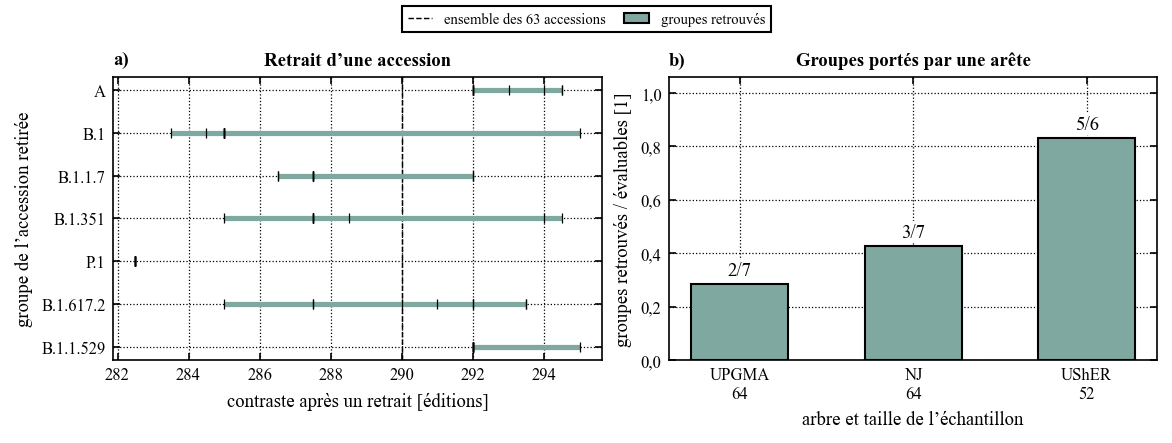

In [23]:
# Distances agrégées et groupes reconnus sur des arbres aux couvertures différentes.
sv_edit_dir = RES / "phylogeny/sars-edit"
sv_public_dir = RES / "phylogeny/sars-surveillance"
sv_verify = nv_csv(sv_edit_dir / "verification.csv")
assert sv_verify.records.eq(64).all() and sv_verify.pairs.eq(2016).all()
assert {"edlib", "wfa2"} <= set(sv_verify.algorithm) and sv_verify.matrix_sha256.nunique() == 1
sv_dist = nv_csv(sv_edit_dir / "pooled_distances.csv").set_index("comparison").loc[["within", "between"]]
sv_public_groups = nv_csv(sv_public_dir / "group_clades.csv")
sv_groups = pd.concat(
    [nv_csv(sv_edit_dir / "group_clades.csv"), sv_public_groups[sv_public_groups.tree.eq("public")]]
)
sv_groups = sv_groups[sv_groups.members.ge(2)].copy()
sv_groups["positive_edge_match"] = pd.to_numeric(sv_groups.positive_edge_match)
sv_match = (
    sv_groups.groupby("tree").positive_edge_match.agg(["sum", "count"]).loc[["upgma", "nj", "public"]]
)
assert sv_match["count"].tolist() == [7, 7, 6] and sv_match["sum"].tolist() == [2, 3, 5]
sv_splits = nv_csv(sv_public_dir / "shared_splits.csv")
assert sv_splits.tips.eq(52).all()
sv_meta = pd.read_csv(RES / "ncbi/sars_metadata.tsv", sep="	").set_index("id")
sv_meta = sv_meta[sv_meta.group.ne("reference")]
sv_distance = (
    pd.read_csv(sv_edit_dir / "matrix.tsv", sep="	", index_col=0)
    .loc[sv_meta.index, sv_meta.index]
    .to_numpy()
)
assert np.array_equal(sv_distance, sv_distance.T) and np.all(np.diag(sv_distance) == 0)
sv_left, sv_right = np.triu_indices(len(sv_meta), 1)
sv_values = sv_distance[sv_left, sv_right]
sv_group = sv_meta.group.to_numpy()
sv_within = sv_group[sv_left] == sv_group[sv_right]
assert int(sv_within.sum()) == 252 and int((~sv_within).sum()) == 1701


def sv_gap(mask):
    return np.median(sv_values[mask & ~sv_within]) - np.median(sv_values[mask & sv_within])


assert sv_dist.loc["within", "median"] == np.median(sv_values[sv_within])
assert sv_dist.loc["between", "median"] == np.median(sv_values[~sv_within])
sv_observed = sv_gap(np.ones(len(sv_values), dtype=bool))
sv_deleted = np.array(
    [sv_gap((sv_left != sv_id) & (sv_right != sv_id)) for sv_id in range(len(sv_group))]
)
sv_fig, sv_ax = plt.subplots(1, 2, figsize=(7.7, 2.85))
for sv_i, sv_name in enumerate(sv_meta.group.unique()):
    sv_selection = sv_deleted[sv_group == sv_name]
    sv_ax[0].hlines(sv_i, np.min(sv_selection), np.max(sv_selection), color=COLORS[2], lw=2.5)
    sv_ax[0].plot(sv_selection, np.full(len(sv_selection), sv_i), marker="|", ls="none", color=INK, ms=5)
sv_ax[0].axvline(sv_observed, **GUIDE, label="ensemble des 63 accessions")
sv_ax[0].set(
    yticks=range(sv_meta.group.nunique()),
    yticklabels=sv_meta.group.unique(),
    xlabel="contraste après un retrait [éditions]",
    ylabel="groupe de l’accession retirée",
)
sv_ax[0].invert_yaxis()
sv_fraction = sv_match["sum"] / sv_match["count"]
sv_ax[1].bar(
    np.arange(3),
    sv_fraction.values,
    width=0.56,
    color=COLORS[2],
    edgecolor=INK,
    label="groupes retrouvés",
)
for sv_i, (sv_kind, sv_row) in enumerate(sv_match.iterrows()):
    sv_ax[1].annotate(
        f"{int(sv_row['sum'])}/{int(sv_row['count'])}",
        (sv_i, sv_fraction.loc[sv_kind]),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        bbox=dict(facecolor=PAPER, edgecolor=PAPER, pad=0.4),
    )
sv_ax[1].set(
    ylabel="groupes retrouvés / évaluables [1]",
    xlabel="arbre et taille de l’échantillon",
    ylim=(0, 1.06),
)
sv_ax[1].set_xticks(np.arange(3), ["UPGMA\n64", "NJ\n64", "UShER\n52"])
for sv_stat, sv_value in [
    ("full", sv_observed),
    ("deletion_min", sv_deleted.min()),
    ("deletion_max", sv_deleted.max()),
]:
    nv_stats.add(
        22,
        "between_minus_within",
        sv_stat,
        "63_accessions",
        [sv_value],
        "finite_panel",
        independent=False,
    )
label_panels(sv_ax)
column_titles(sv_ax, ("Retrait d’une accession", "Groupes portés par une arête"))
legend_above(sv_fig, sv_ax, ncol=2)
nv_save(sv_fig, "biology/phylogenie_surveillance")

*Figure 22.* Chaque trait du panneau a) correspond au retrait d’une accession de son groupe. Le segment montre l’étendue des neuf retraits et la ligne pointillée le contraste du panneau complet. Les fractions du panneau b) comptent tous les groupes évaluables de chaque arbre.

<sub>Code : [scripts/phylogeny/phylo_groups.py](../scripts/phylogeny/phylo_groups.py), [results/phylogeny/sars-edit/verification.csv](../results/phylogeny/sars-edit/verification.csv), [results/phylogeny/sars-edit/pooled_distances.csv](../results/phylogeny/sars-edit/pooled_distances.csv), [results/phylogeny/sars-edit/group_clades.csv](../results/phylogeny/sars-edit/group_clades.csv), [results/phylogeny/sars-surveillance/group_clades.csv](../results/phylogeny/sars-surveillance/group_clades.csv), [results/phylogeny/sars-surveillance/shared_splits.csv](../results/phylogeny/sars-surveillance/shared_splits.csv), [results/phylogeny/sars-edit/censored.csv](../results/phylogeny/sars-edit/censored.csv), [results/phylogeny/sars-surveillance/overlap.csv](../results/phylogeny/sars-surveillance/overlap.csv), [results/ncbi/sars_metadata.tsv](../results/ncbi/sars_metadata.tsv), [results/phylogeny/sars-edit/matrix.tsv](../results/phylogeny/sars-edit/matrix.tsv).</sub>

Les 252 paires d’un même groupe ont une distance médiane de 112 éditions. Pour les 1 701 paires entre groupes, la médiane atteint 402. Les 63 retraits donnent un contraste compris entre 282,5 et 295 éditions, contre 290 pour l’ensemble. Cette étendue mesure la sensibilité au choix d’une accession dans ce panneau.

UPGMA retrouve deux des sept groupes et Neighbor-Joining en retrouve trois. Sur les feuilles représentées dans la référence publique, UShER en retrouve cinq sur six. Une comparaison distincte reconstruit les deux arbres de distances sur les mêmes 52 feuilles. Parmi les 27 bipartitions non triviales de longueur positive dans l’arbre public, six apparaissent sous UPGMA et huit sous Neighbor-Joining. Ce recouvrement décrit les topologies pour la sélection observée. NvPD a vérifié séparément les 2 016 coûts en 268,83 s sur Apple M1 Pro, en distribuant les paires entre six processus à un fil. Le calcul qui répartissait huit fils sur les colonnes d’une seule paire a atteint sa limite de 1 200 s pour la matrice. La comparaison littérale inclut 65 588 symboles ambigus sur 1 905 372 caractères.

Le choix d’un calcul de distance gagne ainsi à préciser le coût observé et l’usage prévu des résultats.

<p><strong><u>Synthèse.</u></strong> Sur les 1 326 paires communes, la corrélation de Pearson entre distance d’édition et chemin UShER vaut 0,124.<br>Les deux mesures portent sur des objets différents, les chaînes déposées et les branches d’un arbre de placement.</p>

<a id="synthese"></a>

## Conclusion et critères de choix

<hr>

La figure 23 compare le temps par paire et le débit d’une collection pour situer le choix de l’algorithme et de sa répartition.

Pour deux chaînes $a,b$, la distance $d(a,b)=\min_{\pi}(N_{\rm ins}+N_{\rm del}+N_{\rm sub})$ minimise le coût parmi les alignements globaux $\pi$. Une programmation dynamique dense parcourt $mn$ cases. Une méthode sensible au score réduit le nombre d’états à explorer lorsque $d$ est faible. Pour $N$ séquences, le lot contient $P=N(N-1)/2$ comparaisons indépendantes et son débit vaut $P/T$.

La synthèse reprend deux expériences indépendantes. La première compare, après lecture du FASTA, NvPD sur GH200 aux bibliothèques monofil sur le processeur Grace du même nœud, après chauffe. La seconde mesure le débit de matrices complètes avec un ou deux nœuds EPYC, chacune contenant 64 séquences. Chaque panneau conserve son propre matériel et son périmètre de temps.

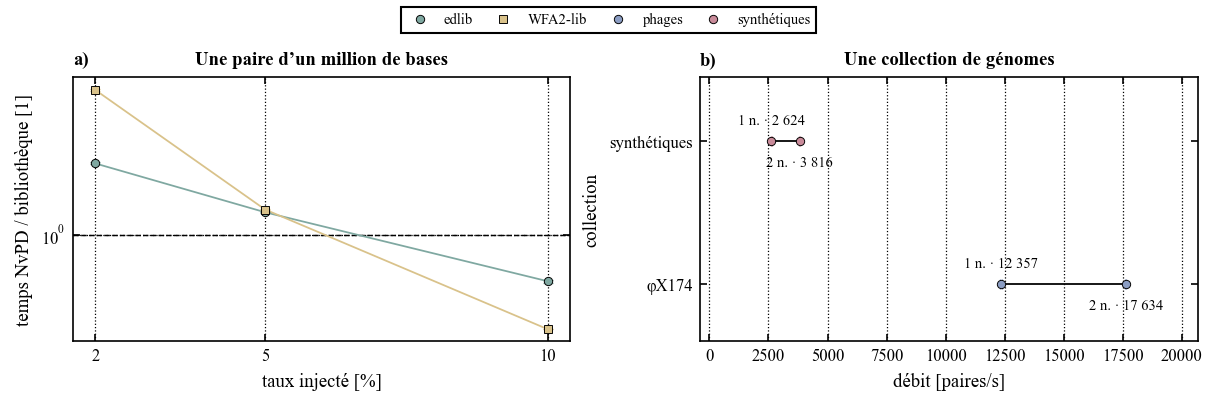

In [24]:
# Choix de la méthode et débit des collections, à partir des mesures brutes.
sy_rep = nv_csv(RES / "repeated/gh200/trials.csv")
sy_pairs = sy_rep[sy_rep.warmup.eq(0) & sy_rep.case.str.startswith("syn-1000000-")].copy()
sy_pairs["rate"] = sy_pairs.case.str.rsplit("-", n=1).str[-1].astype(float)
assert sy_pairs.groupby("case").distance.nunique().eq(1).all()
sy_times = sy_pairs.pivot(index=["rate", "block"], columns="algorithm", values="seconds")
assert sy_times.notna().all().all()
sy_batch = nv_csv(RES / "mpi/scaling/trials.csv")
sy_batch = sy_batch[sy_batch.study.eq("strong")]
sy_batch = sy_batch[sy_batch.case.isin(["synthetic64", "phix64"])]
assert sy_batch.pairs.eq(2016).all()
sy_fig, sy_ax = plt.subplots(1, 2, figsize=(8.0, 2.6))
for sy_j, (sy_alg, sy_lab) in enumerate([("edlib", "edlib"), ("wfa2", "WFA2-lib")]):
    sy_ratio = (sy_times["nvpd-cuda"] / sy_times[sy_alg]).droplevel("block")
    nv_plot(
        sy_ax[0],
        sy_ratio,
        [0.02, 0.05, 0.10],
        [2, 5, 10],
        23,
        "paired_speedup",
        sy_alg,
        "paired_process_block",
        COLORS[sy_j + 2],
        "os"[sy_j],
        joined=True,
        label=sy_lab,
    )
sy_ax[0].axhline(1, **GUIDE)
sy_ax[0].set(
    xlabel="taux injecté [%]", ylabel="temps NvPD / bibliothèque [1]", yscale="log", xticks=[2, 5, 10]
)
for sy_i, (sy_key, sy_lab) in enumerate([("phix64", "phages"), ("synthetic64", "synthétiques")]):
    sy_selected = sy_batch[sy_batch.case.eq(sy_key)].set_index("nodes")
    sy_rates = sy_selected.pairs / sy_selected.seconds
    sy_mean = nv_plot(
        sy_ax[1],
        sy_rates,
        [1, 2],
        [sy_i, sy_i],
        23,
        "pairs_per_second",
        sy_key,
        "independent_mpirun",
        COLORS[sy_i],
        "o",
        horizontal=True,
        label=sy_lab,
    )
    join(sy_ax[1], [sy_i, sy_i], sy_mean, INK, horizontal=True)
    for sy_index, sy_val in enumerate(sy_mean):
        sy_ax[1].annotate(
            f"{sy_index + 1} n. · {sy_val:,.0f}".replace(",", " "),
            (sy_val, sy_i),
            xytext=(0, 8 if sy_index == 0 else -12),
            textcoords="offset points",
            ha="center",
            fontsize=7,
        )
sy_ax[1].set(
    yticks=[0, 1],
    yticklabels=["φX174", "synthétiques"],
    ylim=(-0.4, 1.45),
    xlabel="débit [paires/s]",
    ylabel="collection",
)
sy_ax[1].margins(x=0.20)
sy_ax[1].grid(False, axis="y")
label_panels(sy_ax)
column_titles(sy_ax, ("Une paire d’un million de bases", "Une collection de génomes"))
legend_above(sy_fig, sy_ax, ncol=4)
nv_save(sy_fig, "comparison/synthese")

nv_stats.export(FIG / "statistics.csv")
ct_plot.montage(
    FIG,
    [
        ("comparison/temps_distance.png", "Coût du calcul de la distance globale"),
        ("cpu/echelle_cpu.png", "Passage à l’échelle sur un processeur"),
        ("cpu/openmp_un_million.png", "Anti-diagonales et lignes de grande largeur"),
        ("cpu/variantes_cpu.png", "Vectorisation de la récurrence de dernière occurrence"),
        ("cpu/memoire_cpu.png", "Occupation mémoire et défauts du cache de données"),
        ("cpu/trace_lineaire.png", "Reconstruction de l’alignement en espace linéaire"),
        ("cpu/cout_instructions.png", "Instructions et prédictions de branchement"),
        ("gpu/variantes_gpu.png", "Regroupement des lignes en tuiles CUDA"),
        ("gpu/trace_cuda.png", "Chronologie des appels hôte et des noyaux CUDA"),
        ("gpu/localite_gpu.png", "Localité des lectures en mémoire globale"),
        ("gpu/front_gpu.png", "Calcul par fronts de coût sur accélérateur"),
        ("gpu/allocations_cuda.png", "Réutilisation des tampons entre alignements"),
        ("distributed/portage_kokkos.png", "Portabilité de la récurrence avec Kokkos"),
        ("distributed/echelle_mpi.png", "Passage à l’échelle fort entre nœuds"),
        ("distributed/collectives_mpi.png", "Temps passé dans les échanges collectifs"),
        ("distributed/mpi_faible.png", "Passage à l’échelle faible entre nœuds"),
        ("biology/chromosome21.png", "Distances entre assemblages d’un chromosome humain"),
        ("biology/chromosomes_entiers.png", "Comparaison de chromosomes humains entiers"),
        ("comparison/methodes_exactes.png", "Méthodes exactes sensibles à la distance"),
        ("comparison/quicked.png", "Justesse et coût de la certification de QuickEd"),
        ("biology/phylogenie.png", "Structure des distances entre génomes de phages"),
        ("biology/phylogenie_surveillance.png", "Concordance avec les groupes de surveillance"),
        ("comparison/synthese.png", "Conclusion et critères de choix"),
    ],
)

*Figure 23.* À gauche, le rapport est apparié dans des blocs de processus neufs et préchauffés sur le même GH200, à raison d’un FASTA fixé par taux. À droite, un segment relie les débits de la même matrice sur un ou deux nœuds. Le débit résume sept lancements MPI indépendants, chacun précédé de deux alignements de chauffe.

<sub>Code : [bench/repeated/measure.py](../bench/repeated/measure.py), [results/repeated/gh200/trials.csv](../results/repeated/gh200/trials.csv), [bench/mpi/scaling.py](../bench/mpi/scaling.py), [results/mpi/scaling/trials.csv](../results/mpi/scaling/trials.csv).</sub>

La distance et la granularité du travail commandent deux décisions distinctes. Pour une paire très longue à faible coût, un front étroit évite une grande part du rectangle de programmation dynamique. Lorsque le coût augmente, le calcul dense sur GPU devient compétitif sur les entrées mesurées. Dans une collection, attribuer une paire entière à un travailleur limite les communications entre lignes. Les arbres construits ensuite restent des approximations des distances entre les chaînes déposées. Une expérience de suivi tirerait plusieurs paires indépendantes à chaque taux proche du croisement WFA2-lib/NvPD. Répéter le chronométrage sur chaque paire permettrait alors de distinguer la variation entre entrées de celle des temps à entrée fixée.

<p><strong><u>Synthèse.</u></strong> À un million de bases, le rapport moyen NvPD/WFA2-lib vaut 4,65 à 2 % et 0,37 à 10 %.<br>Le choix de la méthode dépend donc à la fois du score attendu, du matériel et du nombre de paires disponibles.</p>